In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [2]:
df = pd.read_csv("../data/rolling_stones_spotify.csv")

In [3]:
df.head()

,Unnamed: 0,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
0,0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,1,2IEkywLJ4ykbhi1yRQvmsT,spotify:track:2IEkywLJ4ykbhi1yRQvmsT,0.0824,0.4630,0.9930,0.9960,0.9320,-12.9130,0.1100,118.0010,0.0302,33,48640
1,1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,2,6GVgVJBKkGJoRfarYRvGTU,spotify:track:6GVgVJBKkGJoRfarYRvGTU,0.4370,0.3260,0.9650,0.2330,0.9610,-4.8030,0.0759,131.4550,0.3180,34,253173
2,2,Start Me Up - Live,Licked Live In NYC,2022-06-10,3,1Lu761pZ0dBTGpzxaQoZNW,spotify:track:1Lu761pZ0dBTGpzxaQoZNW,0.4160,0.3860,0.9690,0.4000,0.9560,-4.9360,0.1150,130.0660,0.3130,34,263160
3,3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,4,1agTQzOTUnGNggyckEqiDH,spotify:track:1agTQzOTUnGNggyckEqiDH,0.5670,0.3690,0.9850,0.0001,0.8950,-5.5350,0.1930,132.9940,0.1470,32,305880
4,4,Don’t Stop - Live,Licked Live In NYC,2022-06-10,5,7piGJR8YndQBQWVXv6KtQw,spotify:track:7piGJR8YndQBQWVXv6KtQw,0.4000,0.3030,0.9690,0.0559,0.9660,-5.0980,0.0930,130.5330,0.2060,32,305106


In [4]:
df.tail()

,Unnamed: 0,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
1605,1605,Carol,The Rolling Stones,1964-04-16,8,08l7M5UpRnffGl0FyuRiQZ,spotify:track:08l7M5UpRnffGl0FyuRiQZ,0.1570,0.4660,0.9320,0.0062,0.3240,-9.2140,0.0429,177.3400,0.9670,39,154080
1606,1606,Tell Me,The Rolling Stones,1964-04-16,9,3JZllQBsTM6WwoJdzFDLhx,spotify:track:3JZllQBsTM6WwoJdzFDLhx,0.0576,0.5090,0.7060,0.0000,0.5160,-9.4270,0.0843,122.0150,0.4460,36,245266
1607,1607,Can I Get A Witness,The Rolling Stones,1964-04-16,10,0t2qvfSBQ3Y08lzRRoVTdb,spotify:track:0t2qvfSBQ3Y08lzRRoVTdb,0.3710,0.7900,0.7740,0.0000,0.0669,-7.9610,0.0720,97.0350,0.8350,30,176080
1608,1608,You Can Make It If You Try,The Rolling Stones,1964-04-16,11,5ivIs5vwSj0RChOIvlY3On,spotify:track:5ivIs5vwSj0RChOIvlY3On,0.2170,0.7000,0.5460,0.0001,0.1660,-9.5670,0.0622,102.6340,0.5320,27,121680
1609,1609,Walking The Dog,The Rolling Stones,1964-04-16,12,43SkTJJ2xleDaeiE4TIM70,spotify:track:43SkTJJ2xleDaeiE4TIM70,0.3830,0.7270,0.9340,0.0685,0.0965,-8.3730,0.0359,125.2750,0.9690,35,189186


In [5]:
df.shape

(1610, 18)

In [6]:
df.columns.tolist()

['Unnamed: 0',
 'name',
 'album',
 'release_date',
 'track_number',
 'id',
 'uri',
 'acousticness',
 'danceability',
 'energy',
 'instrumentalness',
 'liveness',
 'loudness',
 'speechiness',
 'tempo',
 'valence',
 'popularity',
 'duration_ms']

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1610 non-null   int64  
 1   name              1610 non-null   str    
 2   album             1610 non-null   str    
 3   release_date      1610 non-null   str    
 4   track_number      1610 non-null   int64  
 5   id                1610 non-null   str    
 6   uri               1610 non-null   str    
 7   acousticness      1610 non-null   float64
 8   danceability      1610 non-null   float64
 9   energy            1610 non-null   float64
 10  instrumentalness  1610 non-null   float64
 11  liveness          1610 non-null   float64
 12  loudness          1610 non-null   float64
 13  speechiness       1610 non-null   float64
 14  tempo             1610 non-null   float64
 15  valence           1610 non-null   float64
 16  popularity        1610 non-null   int64  
 17  durati

In [8]:
df.describe()

,Unnamed: 0,track_number,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
count,1610.0000,1610.0000,1610.0000,1610.0000,1610.0000,1610.0000,1610.0000,1610.0000,1610.0000,1610.0000,1610.0000,1610.0000,1610.0000
mean,804.5000,8.6137,0.2505,0.4689,0.7924,0.1642,0.4917,-6.9716,0.0695,126.0820,0.5822,20.7882,257736.4882
std,464.9113,6.5602,0.2274,0.1418,0.1799,0.2762,0.3491,2.9940,0.0516,29.2335,0.2313,12.4269,108333.4749
min,0.0000,1.0000,0.0000,0.1040,0.1410,0.0000,0.0219,-24.4080,0.0232,46.5250,0.0000,0.0000,21000.0000
25%,402.2500,4.0000,0.0583,0.3622,0.6740,0.0002,0.1530,-8.9825,0.0365,107.3907,0.4042,13.0000,190613.0000
50%,804.5000,7.0000,0.1830,0.4580,0.8485,0.0138,0.3795,-6.5230,0.0512,124.4045,0.5830,20.0000,243093.0000
75%,1206.7500,11.0000,0.4038,0.5780,0.9450,0.1790,0.8938,-4.6087,0.0866,142.3558,0.7780,27.0000,295319.7500
max,1609.0000,47.0000,0.9940,0.8870,0.9990,0.9960,0.9980,-1.0140,0.6240,216.3040,0.9740,80.0000,981866.0000


In [9]:
df.isnull().sum()

Unnamed: 0          0
name                0
album               0
release_date        0
track_number        0
id                  0
uri                 0
acousticness        0
danceability        0
energy              0
instrumentalness    0
liveness            0
loudness            0
speechiness         0
tempo               0
valence             0
popularity          0
duration_ms         0
dtype: int64

In [10]:
missing = (df.isnull().sum()/len(df))*100

missing.sort_values(ascending=False)

Unnamed: 0         0.0000
name               0.0000
album              0.0000
release_date       0.0000
track_number       0.0000
id                 0.0000
uri                0.0000
acousticness       0.0000
danceability       0.0000
energy             0.0000
instrumentalness   0.0000
liveness           0.0000
loudness           0.0000
speechiness        0.0000
tempo              0.0000
valence            0.0000
popularity         0.0000
duration_ms        0.0000
dtype: float64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
if "id" in df.columns:
    duplicate_ids = df["id"].duplicated().sum()
    print(f"Duplicate Spotify IDs: {duplicate_ids}")

Duplicate Spotify IDs: 0


In [13]:
if "id" in df.columns:
    duplicate_id_rows = df[df["id"].duplicated(keep=False)].sort_values("id")
    duplicate_id_rows

In [14]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for column in categorical_columns:
    print(f"\n{'=' * 60}")
    print(f"Column: {column}")
    print(f"Unique values: {df[column].nunique(dropna=False)}")


Column: name
Unique values: 954

Column: album
Unique values: 90

Column: release_date
Unique values: 57

Column: id
Unique values: 1610

Column: uri
Unique values: 1610


C:\Users\SATTIE\AppData\Local\Temp\ipykernel_33732\2258724171.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [15]:
if "album" in df.columns:
    album_counts = df["album"].value_counts()

    print(f"Number of unique albums: {album_counts.shape[0]}")
    display(album_counts.to_frame("Number of Songs"))

Number of unique albums: 90


,Number of Songs
album,
Voodoo Lounge Uncut (Live),56
Honk (Deluxe),47
Tattoo You (Super Deluxe),46
Live Licks,46
Some Girls (Deluxe Version),44
Goats Head Soup (Deluxe),37
Flashpoint,34
Sticky Fingers (Super Deluxe),33
On Air (Deluxe),32


C:\Users\SATTIE\AppData\Local\Temp\ipykernel_33732\3042700909.py:10: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


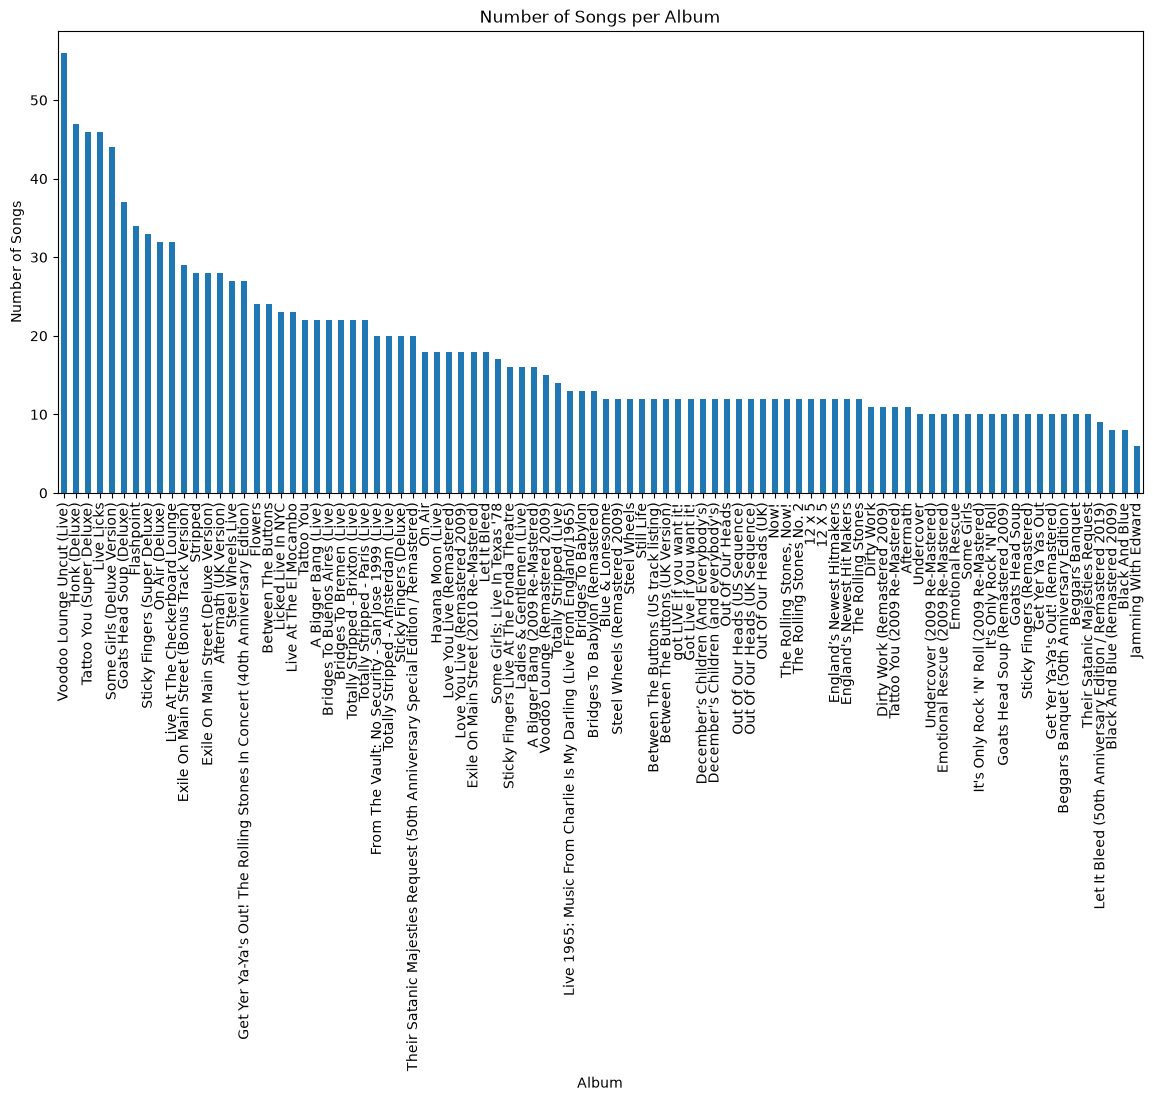

In [16]:
if "album" in df.columns:
    plt.figure(figsize=(14, 6))

    album_counts.sort_values(ascending=False).plot(kind="bar")

    plt.title("Number of Songs per Album")
    plt.xlabel("Album")
    plt.ylabel("Number of Songs")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

In [17]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

df[numerical_columns].describe().T

Numerical columns:
['Unnamed: 0', 'track_number', 'acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'popularity', 'duration_ms']


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1610.0000,804.5000,464.9113,0.0000,402.2500,804.5000,1206.7500,1609.0000
track_number,1610.0000,8.6137,6.5602,1.0000,4.0000,7.0000,11.0000,47.0000
acousticness,1610.0000,0.2505,0.2274,0.0000,0.0583,0.1830,0.4038,0.9940
danceability,1610.0000,0.4689,0.1418,0.1040,0.3622,0.4580,0.5780,0.8870
energy,1610.0000,0.7924,0.1799,0.1410,0.6740,0.8485,0.9450,0.9990
instrumentalness,1610.0000,0.1642,0.2762,0.0000,0.0002,0.0138,0.1790,0.9960
liveness,1610.0000,0.4917,0.3491,0.0219,0.1530,0.3795,0.8938,0.9980
loudness,1610.0000,-6.9716,2.9940,-24.4080,-8.9825,-6.5230,-4.6087,-1.0140
speechiness,1610.0000,0.0695,0.0516,0.0232,0.0365,0.0512,0.0866,0.6240
tempo,1610.0000,126.0820,29.2335,46.5250,107.3907,124.4045,142.3558,216.3040


In [18]:
expected_ranges = {
    "acousticness": (0, 1),
    "danceability": (0, 1),
    "energy": (0, 1),
    "instrumentalness": (0, 1),
    "liveness": (0, 1),
    "speechiness": (0, 1),
    "valence": (0, 1),
    "popularity": (0, 100),
}

range_check = []

for column, (minimum, maximum) in expected_ranges.items():
    if column in df.columns:
        invalid_count = (
            (df[column] < minimum) |
            (df[column] > maximum)
        ).sum()

        range_check.append({
            "Feature": column,
            "Expected Min": minimum,
            "Expected Max": maximum,
            "Actual Min": df[column].min(),
            "Actual Max": df[column].max(),
            "Invalid Values": invalid_count
        })

range_check_df = pd.DataFrame(range_check)

display(range_check_df)

,Feature,Expected Min,Expected Max,Actual Min,Actual Max,Invalid Values
0,acousticness,0,1,0.0000,0.9940,0
1,danceability,0,1,0.1040,0.8870,0
2,energy,0,1,0.1410,0.9990,0
3,instrumentalness,0,1,0.0000,0.9960,0
4,liveness,0,1,0.0219,0.9980,0
5,speechiness,0,1,0.0232,0.6240,0
6,valence,0,1,0.0000,0.9740,0
7,popularity,0,100,0.0000,80.0000,0


In [19]:
if "duration_ms" in df.columns:
    print(df["duration_ms"].describe())

if "duration_ms" in df.columns:
    print(
        f"Minimum duration: {df['duration_ms'].min():,.0f} ms"
    )
    print(
        f"Maximum duration: {df['duration_ms'].max():,.0f} ms"
    )

count     1610.0000
mean    257736.4882
std     108333.4749
min      21000.0000
25%     190613.0000
50%     243093.0000
75%     295319.7500
max     981866.0000
Name: duration_ms, dtype: float64
Minimum duration: 21,000 ms
Maximum duration: 981,866 ms


In [20]:
if "tempo" in df.columns:
    print(df["tempo"].describe())

if "tempo" in df.columns:
    print("Potentially unusual tempo values:")
    display(
        df[df["tempo"] <= 0][["name", "tempo"]]
        if "name" in df.columns
        else df[df["tempo"] <= 0][["tempo"]]
    )

count   1610.0000
mean     126.0820
std       29.2335
min       46.5250
25%      107.3907
50%      124.4045
75%      142.3558
max      216.3040
Name: tempo, dtype: float64
Potentially unusual tempo values:


,name,tempo


In [21]:
if "loudness" in df.columns:
    print(df["loudness"].describe())

if "loudness" in df.columns:
    suspicious_loudness = df[
        (df["loudness"] < -60) |
        (df["loudness"] > 0)
    ]

    print(
        f"Values outside the typical -60 to 0 dB range: "
        f"{len(suspicious_loudness)}"
    )

count   1610.0000
mean      -6.9716
std        2.9940
min      -24.4080
25%       -8.9825
50%       -6.5230
75%       -4.6087
max       -1.0140
Name: loudness, dtype: float64
Values outside the typical -60 to 0 dB range: 0


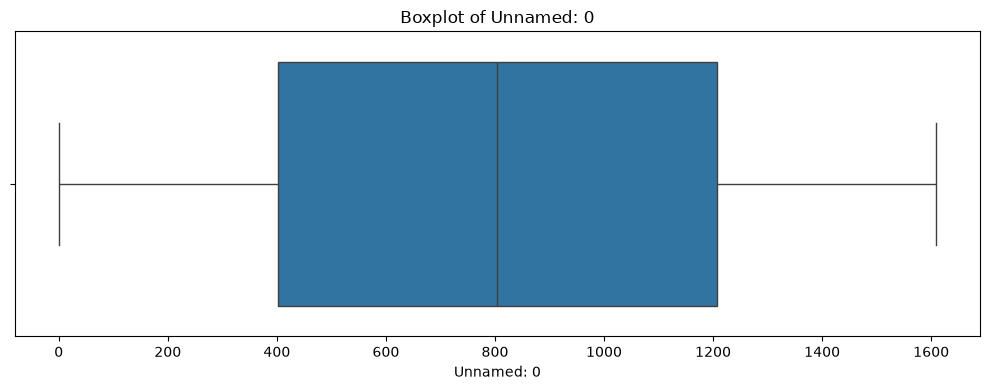

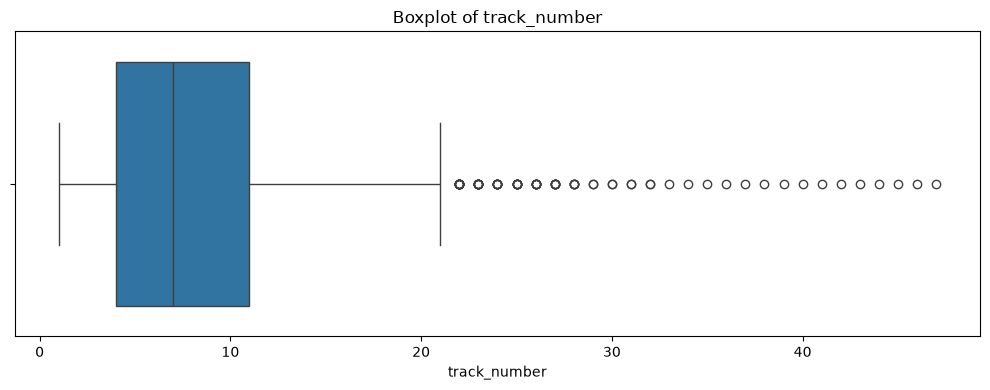

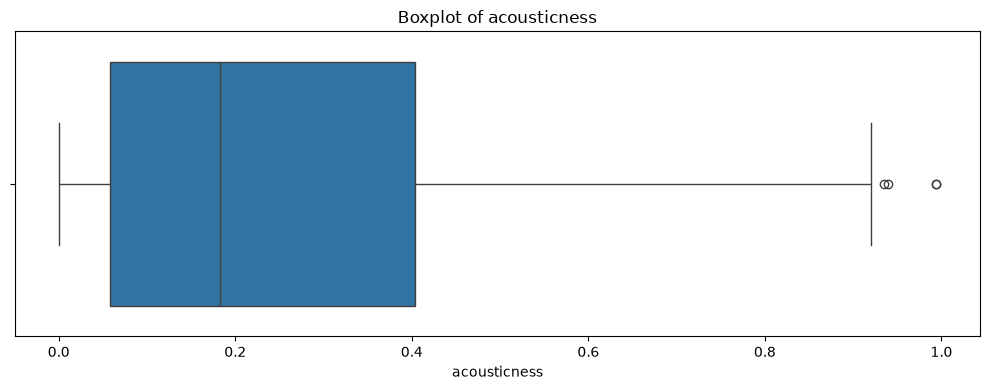

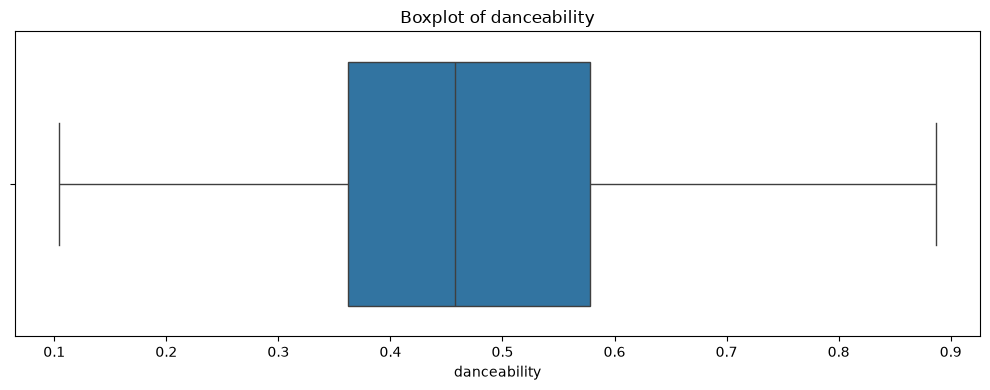

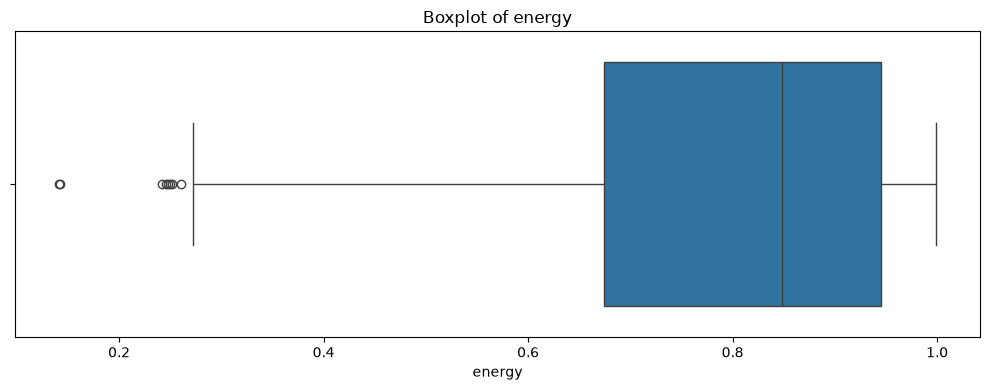

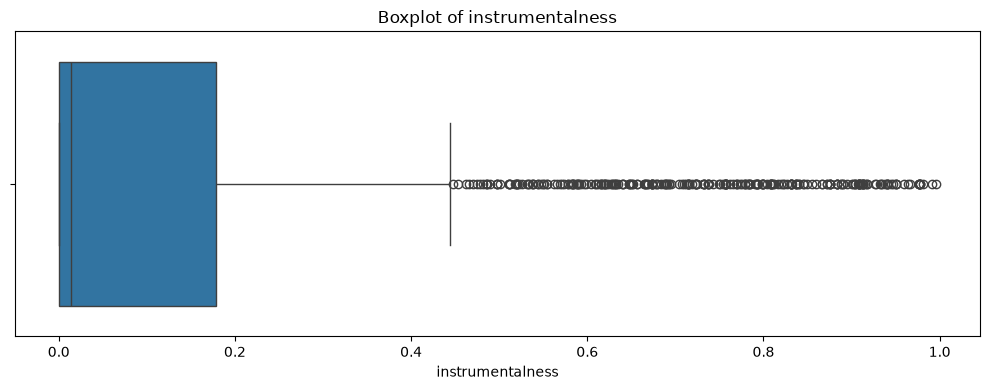

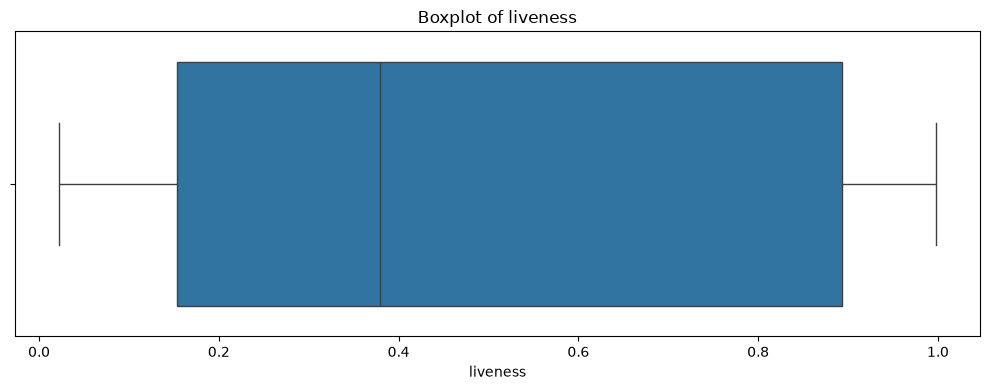

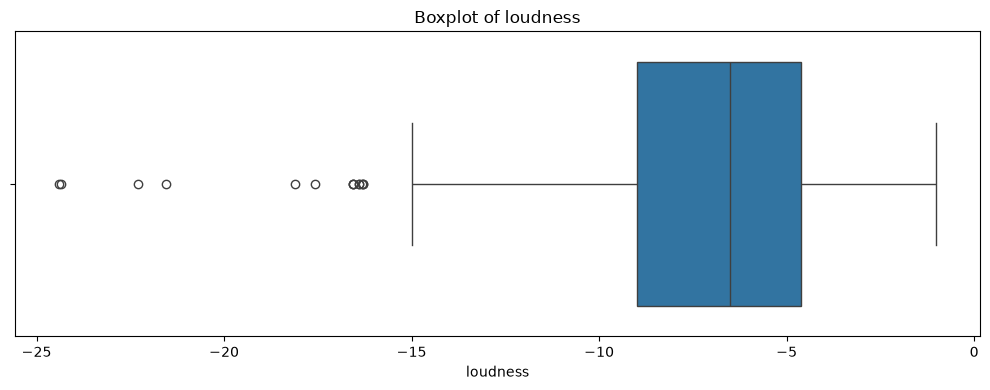

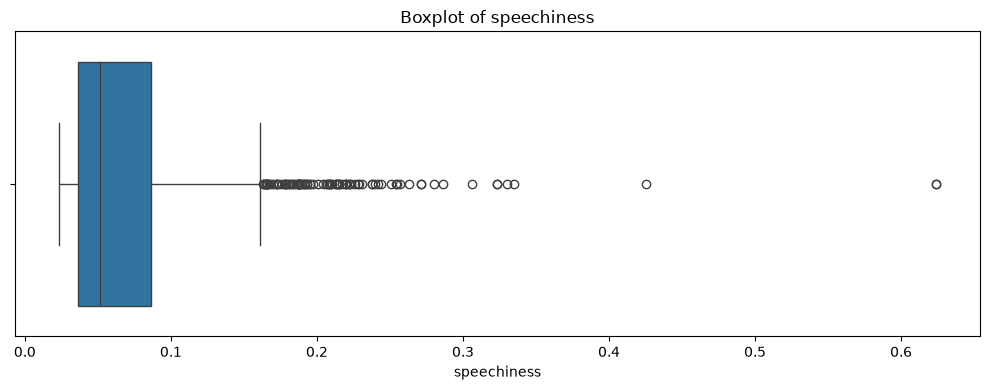

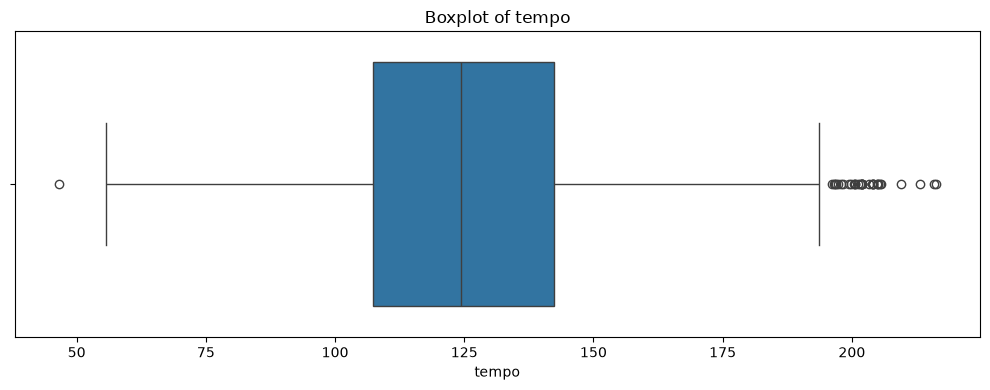

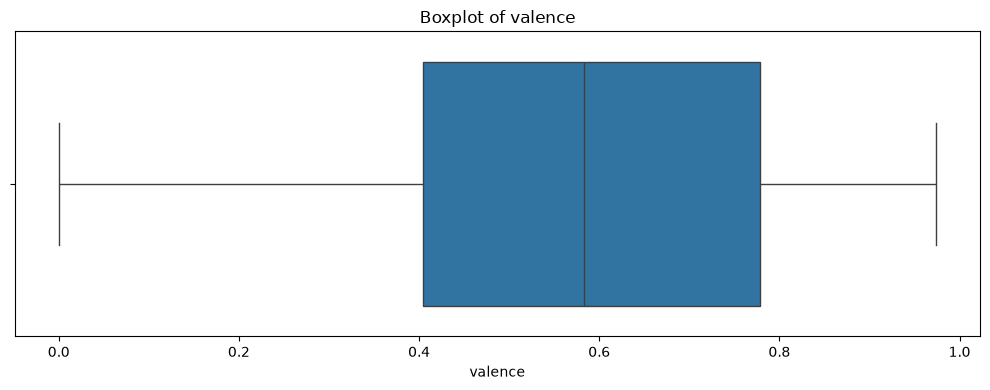

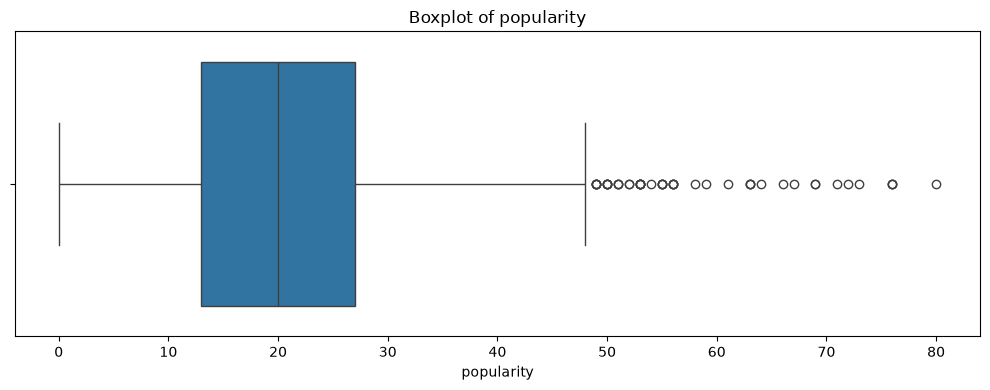

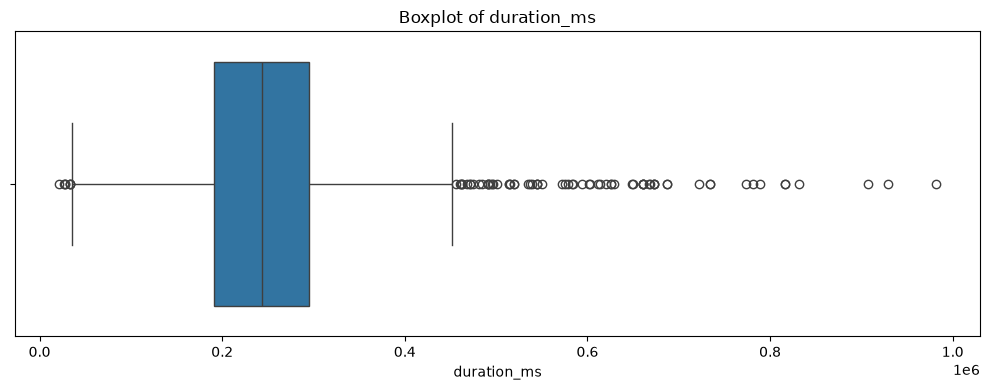

In [22]:
numeric_features = [
    column for column in numerical_columns
    if column in df.columns
]

for column in numeric_features:
    plt.figure(figsize=(10, 4))

    sns.boxplot(x=df[column])

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

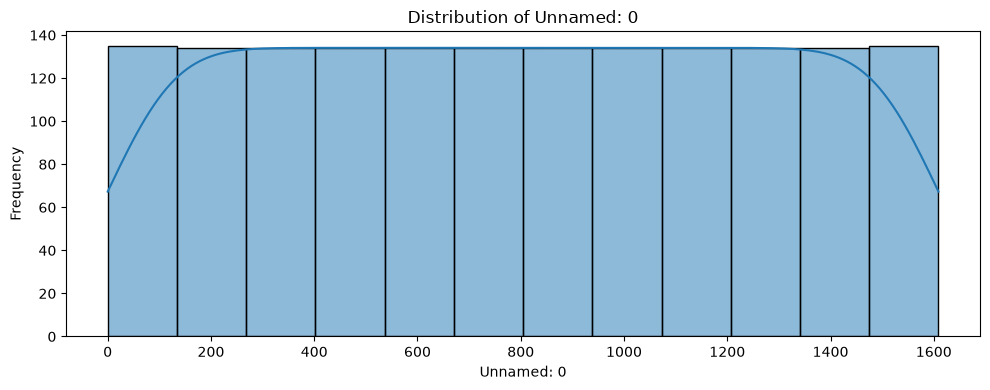

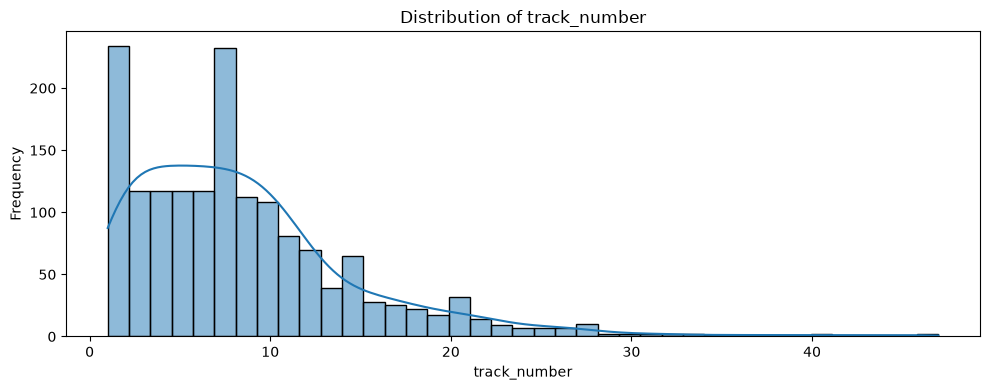

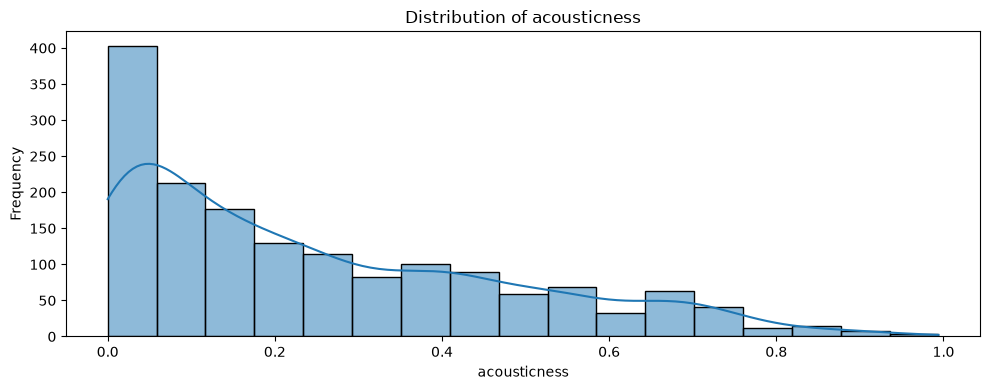

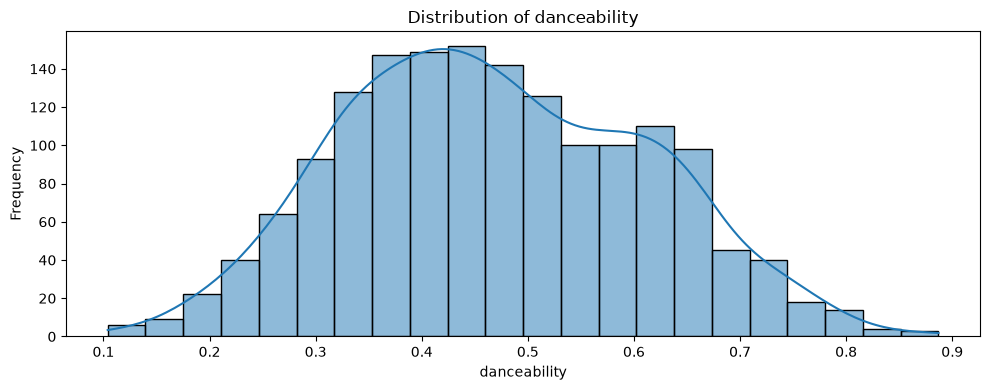

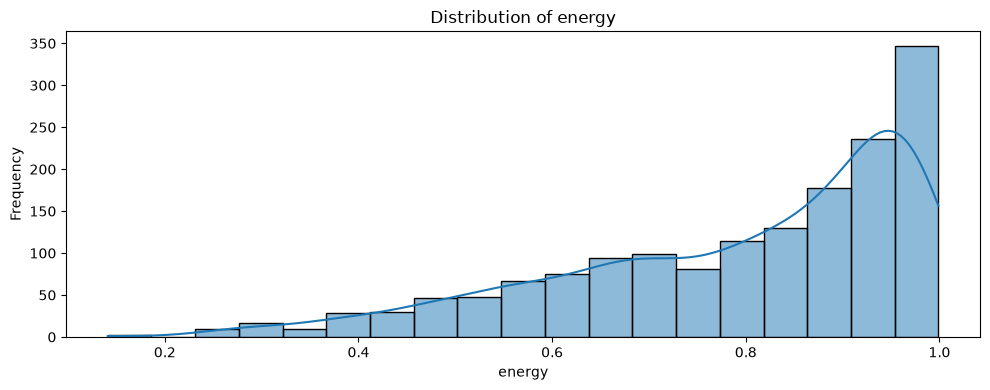

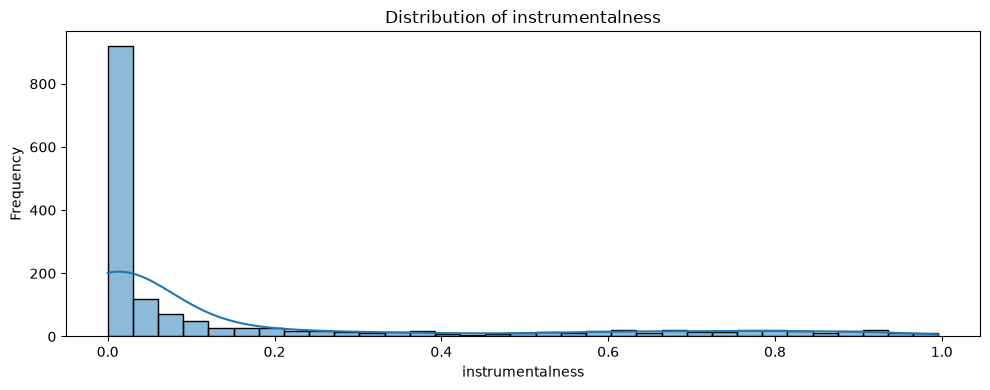

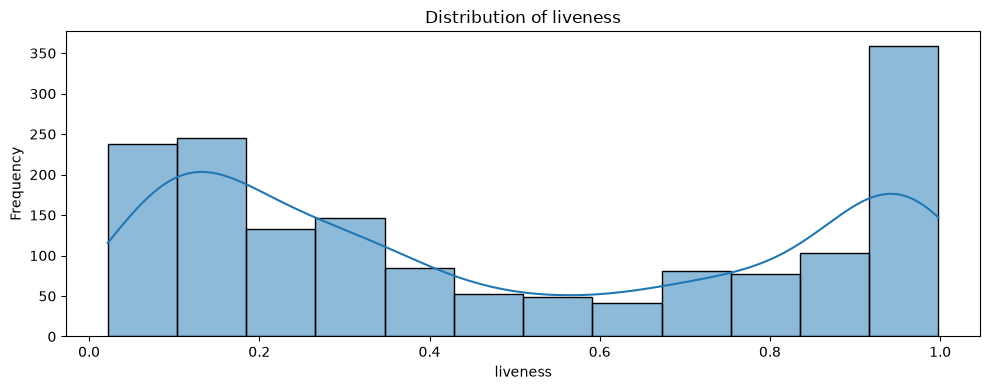

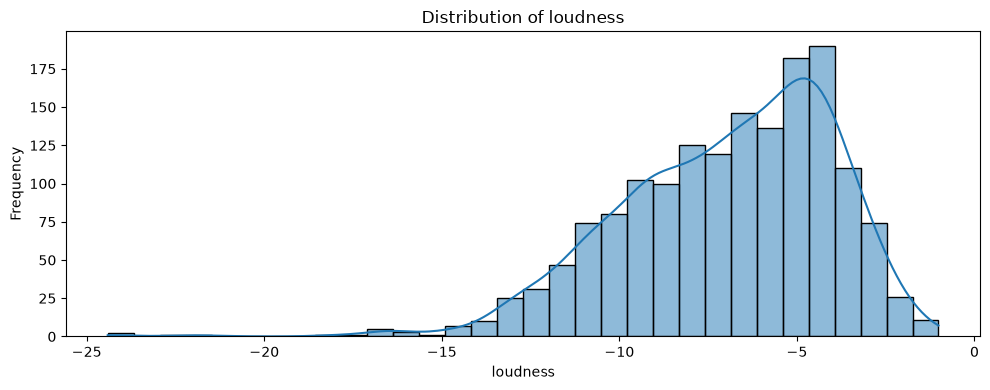

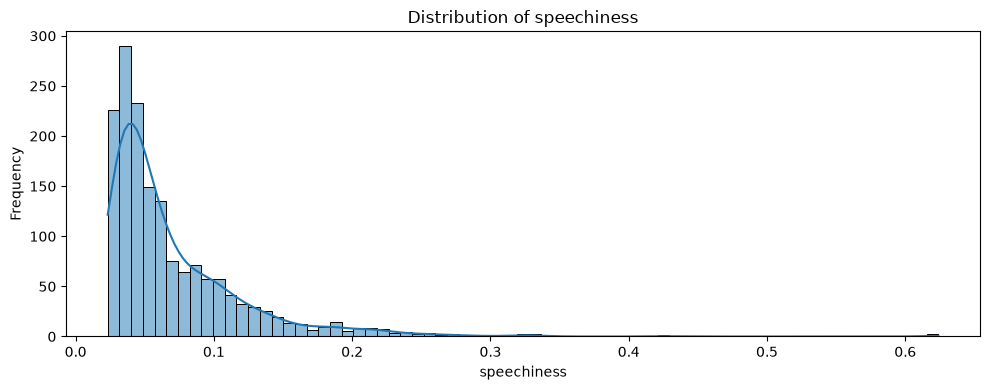

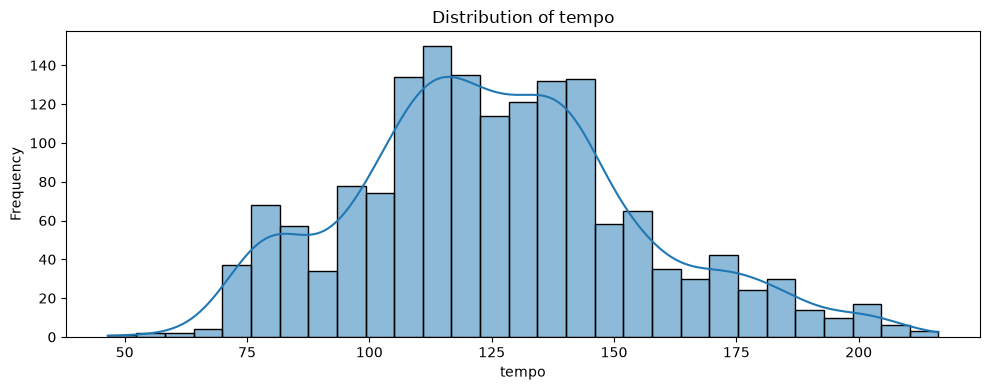

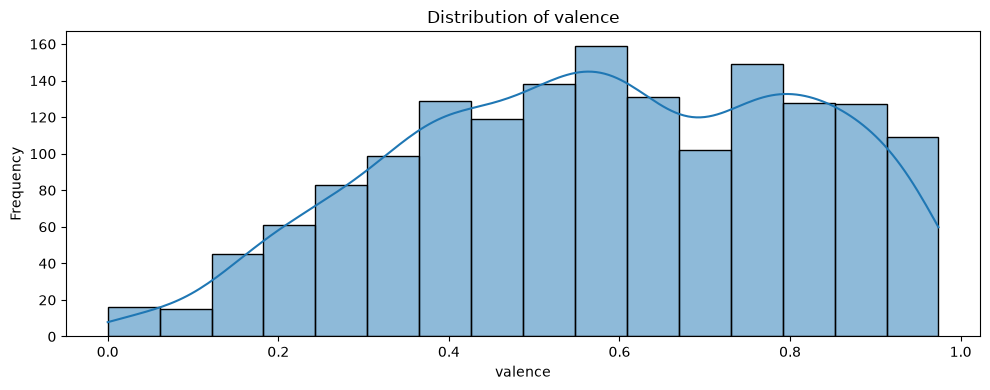

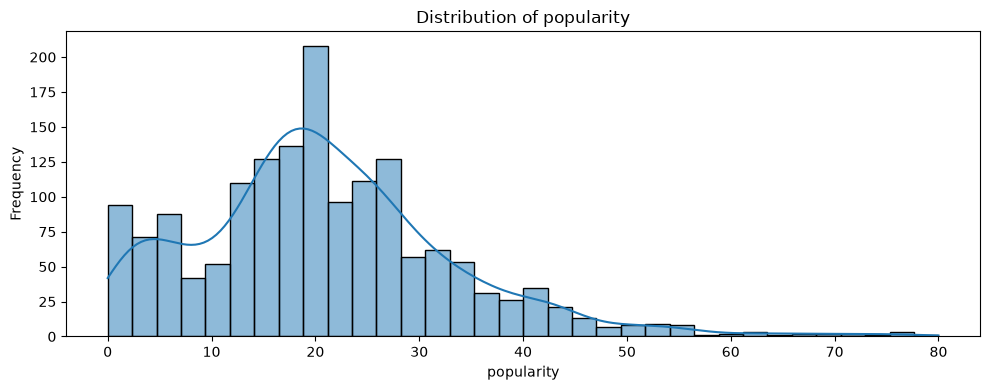

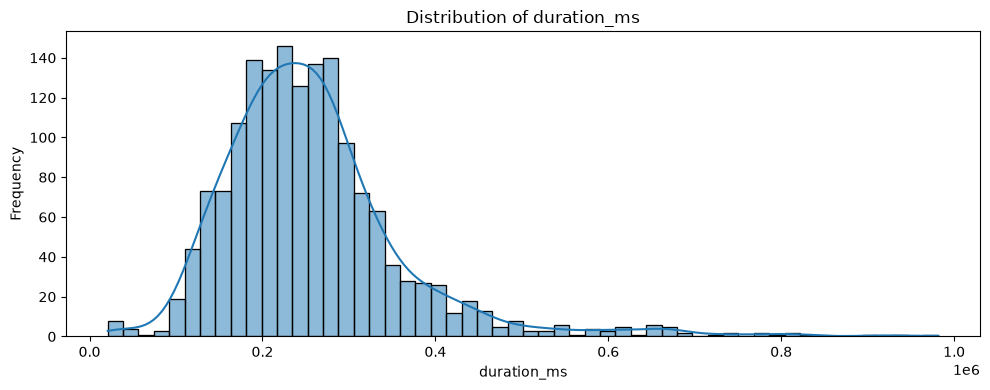

In [23]:
for column in numeric_features:
    plt.figure(figsize=(10, 4))

    sns.histplot(
        data=df,
        x=column,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [24]:
inspection_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null Count": df.notnull().sum(),
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().sum() / len(df)) * 100,
    "Unique Values": df.nunique(dropna=False)
})

display(inspection_summary)

,Data Type,Non-Null Count,Missing Count,Missing %,Unique Values
Unnamed: 0,int64,1610,0,0.0000,1610
name,str,1610,0,0.0000,954
album,str,1610,0,0.0000,90
release_date,str,1610,0,0.0000,57
track_number,int64,1610,0,0.0000,47
id,str,1610,0,0.0000,1610
uri,str,1610,0,0.0000,1610
acousticness,float64,1610,0,0.0000,933
danceability,float64,1610,0,0.0000,518
energy,float64,1610,0,0.0000,511


In [25]:
df_clean = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", df_clean.shape)

Original shape: (1610, 18)
Working copy shape: (1610, 18)


In [26]:
if "Unnamed: 0" in df_clean.columns:
    df_clean = df_clean.drop(columns=["Unnamed: 0"])

print(df_clean.shape)
print(df_clean.columns.tolist())

(1610, 17)
['name', 'album', 'release_date', 'track_number', 'id', 'uri', 'acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'popularity', 'duration_ms']


In [27]:
df_clean = df_clean.reset_index(drop=True)

print(df_clean.index)

RangeIndex(start=0, stop=1610, step=1)


In [28]:
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df_clean.columns.tolist())

['name', 'album', 'release_date', 'track_number', 'id', 'uri', 'acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'popularity', 'duration_ms']


In [29]:
text_columns = [
    "name",
    "album",
    "id",
    "uri"
]

for col in text_columns:
    df_clean[col] = df_clean[col].astype("string")

In [30]:
numeric_columns = [
    "track_number",
    "acousticness",
    "danceability",
    "energy",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "tempo",
    "valence",
    "popularity",
    "duration_ms"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

In [31]:
df_clean["release_date"] = pd.to_datetime(
    df_clean["release_date"],
    errors="coerce"
)

print(df_clean["release_date"].dtype)
print(df_clean["release_date"].head())

datetime64[us]
0   2022-06-10
1   2022-06-10
2   2022-06-10
3   2022-06-10
4   2022-06-10
Name: release_date, dtype: datetime64[us]


In [32]:
missing_after_conversion = df_clean.isnull().sum()

print(missing_after_conversion)

name                0
album               0
release_date        0
track_number        0
id                  0
uri                 0
acousticness        0
danceability        0
energy              0
instrumentalness    0
liveness            0
loudness            0
speechiness         0
tempo               0
valence             0
popularity          0
duration_ms         0
dtype: int64


In [33]:
print(
    "Total missing values:",
    df_clean.isnull().sum().sum()
)

Total missing values: 0


In [34]:
print(
    "Duplicate rows:",
    df_clean.duplicated().sum()
)

print(
    "Duplicate Spotify IDs:",
    df_clean["id"].duplicated().sum()
)

print(
    "Duplicate Spotify URIs:",
    df_clean["uri"].duplicated().sum()
)

Duplicate rows: 0
Duplicate Spotify IDs: 0
Duplicate Spotify URIs: 0


In [35]:
range_results = []

for feature, (minimum, maximum) in expected_ranges.items():

    invalid_values = (
        (df_clean[feature] < minimum) |
        (df_clean[feature] > maximum)
    ).sum()

    range_results.append({
        "Feature": feature,
        "Expected Min": minimum,
        "Expected Max": maximum,
        "Actual Min": df_clean[feature].min(),
        "Actual Max": df_clean[feature].max(),
        "Invalid Values": invalid_values
    })

range_check_df = pd.DataFrame(range_results)

display(range_check_df)

,Feature,Expected Min,Expected Max,Actual Min,Actual Max,Invalid Values
0,acousticness,0,1,0.0000,0.9940,0
1,danceability,0,1,0.1040,0.8870,0
2,energy,0,1,0.1410,0.9990,0
3,instrumentalness,0,1,0.0000,0.9960,0
4,liveness,0,1,0.0219,0.9980,0
5,speechiness,0,1,0.0232,0.6240,0
6,valence,0,1,0.0000,0.9740,0
7,popularity,0,100,0.0000,80.0000,0


In [36]:
invalid_loudness = df_clean[
    (df_clean["loudness"] < -60) |
    (df_clean["loudness"] > 0)
]

print("Invalid loudness values:", len(invalid_loudness))

Invalid loudness values: 0


In [37]:
duration_extremes = df_clean[
    (df_clean["duration_ms"] < 60000) |
    (df_clean["duration_ms"] > 600000)
][
    ["name", "album", "duration_ms"]
].sort_values("duration_ms")

display(duration_extremes)

,name,album,duration_ms
546,Show Intro - Live,Live 1965: Music From Charlie Is My Darling (L...,21000
839,Intro (Take The A Train) - Live / Remastered 2009,Still Life,27293
739,Continental Drift - Live,Flashpoint,27693
756,Continental Drift - Live / Remastered 2009,Flashpoint,28266
553,Charlie's Intro To Little Red Rooster - Live,Live 1965: Music From Charlie Is My Darling (L...,32946
807,Key To The Highway - Piano Instrumental,Dirty Work,33466
818,Key To The Highway - Piano Instrumental/Remast...,Dirty Work (Remastered 2009),33466
547,Everybody Needs Somebody To Love - Live,Live 1965: Music From Charlie Is My Darling (L...,35920
422,Intro - Live,Ladies & Gentlemen (Live),48000
850,Outro - Star Spangled Banner - Live / Remaster...,Still Life,48266


In [38]:
tempo_extremes = df_clean[
    (df_clean["tempo"] < 60) |
    (df_clean["tempo"] > 200)
][
    ["name", "album", "tempo"]
].sort_values("tempo")

display(tempo_extremes)

,name,album,tempo
103,Intro - Live,A Bigger Bang (Live),46.5250
965,"Intro: Excerpt from ""Fanfare For The Common Ma...",Love You Live (Remastered 2009),55.5810
440,Blue And Lonesome,Blue & Lonesome,57.7720
503,Slipping Away - Live,Totally Stripped - Amsterdam (Live),200.3670
361,It's All Over Now - The Joe Loss Pop Show / 1964,On Air,200.6240
379,It's All Over Now - The Joe Loss Pop Show / 1964,On Air (Deluxe),200.6240
975,Mannish Boy - Live / Remastered 2009,Love You Live (Remastered 2009),201.1710
29,Mannish Boy - Live At The El Mocambo 1977,Live At The El Mocambo,201.5850
957,Mannish Boy - Live,Love You Live (Remastered),201.6910
395,If You Need Me - The Joe Loss Pop Show / 1964,On Air (Deluxe),201.8780


In [39]:
df_clean["duration_min"] = (
    df_clean["duration_ms"] / 60000
)

df_clean[
    ["name", "duration_ms", "duration_min"]
].head()

,name,duration_ms,duration_min
0,Concert Intro Music - Live,48640,0.8107
1,Street Fighting Man - Live,253173,4.2195
2,Start Me Up - Live,263160,4.3860
3,If You Can't Rock Me - Live,305880,5.0980
4,Don’t Stop - Live,305106,5.0851


In [40]:
cleaning_summary = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Missing Values",
        "Duplicate Rows",
        "Duplicate Spotify IDs",
        "Duplicate Spotify URIs"
    ],
    "Value": [
        len(df_clean),
        len(df_clean.columns),
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum(),
        df_clean["id"].duplicated().sum(),
        df_clean["uri"].duplicated().sum()
    ]
})

display(cleaning_summary)

,Metric,Value
0,Rows,1610
1,Columns,18
2,Missing Values,0
3,Duplicate Rows,0
4,Duplicate Spotify IDs,0
5,Duplicate Spotify URIs,0


In [41]:
df_clean.to_csv(
    "spotify_rolling_stones_cleaned.csv",
    index=False
)

In [42]:
if "duration_min" in df_clean.columns:
    df_clean = df_clean.drop(columns=["duration_min"])

print(df_clean.shape) #type: ignore

(1610, 17)


In [43]:
print("=" * 60)
print("FINAL DATA CLEANING VALIDATION")
print("=" * 60)

print(f"\nDataset shape: {df_clean.shape}")

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nDuplicate Spotify IDs:")
print(df_clean["id"].duplicated().sum())

print("\nDuplicate Spotify URIs:")
print(df_clean["uri"].duplicated().sum())

print("\nData types:")
print(df_clean.dtypes)

print("\nColumns:")
print(df_clean.columns.tolist())

FINAL DATA CLEANING VALIDATION

Dataset shape: (1610, 17)

Missing values:
0

Duplicate rows:
0

Duplicate Spotify IDs:
0

Duplicate Spotify URIs:
0

Data types:
name                        string
album                       string
release_date        datetime64[us]
track_number                 int64
id                          string
uri                         string
acousticness               float64
danceability               float64
energy                     float64
instrumentalness           float64
liveness                   float64
loudness                   float64
speechiness                float64
tempo                      float64
valence                    float64
popularity                   int64
duration_ms                  int64
dtype: object

Columns:
['name', 'album', 'release_date', 'track_number', 'id', 'uri', 'acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'popularity', 'duration_ms']


In [44]:
df_clean.to_csv(
    "spotify_rolling_stones_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [45]:
feature_columns = [
    "acousticness",
    "danceability",
    "energy",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "tempo",
    "valence",
    "popularity",
    "duration_ms"
]

X = df_clean[feature_columns].copy()

display(X.head())

,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
0,0.0824,0.4630,0.9930,0.9960,0.9320,-12.9130,0.1100,118.0010,0.0302,33,48640
1,0.4370,0.3260,0.9650,0.2330,0.9610,-4.8030,0.0759,131.4550,0.3180,34,253173
2,0.4160,0.3860,0.9690,0.4000,0.9560,-4.9360,0.1150,130.0660,0.3130,34,263160
3,0.5670,0.3690,0.9850,0.0001,0.8950,-5.5350,0.1930,132.9940,0.1470,32,305880
4,0.4000,0.3030,0.9690,0.0559,0.9660,-5.0980,0.0930,130.5330,0.2060,32,305106


In [46]:
print("Feature matrix shape:", X.shape)
print("\nData types:")
print(X.dtypes)

Feature matrix shape: (1610, 11)

Data types:
acousticness        float64
danceability        float64
energy              float64
instrumentalness    float64
liveness            float64
loudness            float64
speechiness         float64
tempo               float64
valence             float64
popularity            int64
duration_ms           int64
dtype: object


In [47]:
feature_summary = pd.DataFrame({
    "Min": X.min(),
    "Max": X.max(),
    "Mean": X.mean(),
    "Std": X.std()
})

display(feature_summary)

,Min,Max,Mean,Std
acousticness,0.0000,0.9940,0.2505,0.2274
danceability,0.1040,0.8870,0.4689,0.1418
energy,0.1410,0.9990,0.7924,0.1799
instrumentalness,0.0000,0.9960,0.1642,0.2762
liveness,0.0219,0.9980,0.4917,0.3491
loudness,-24.4080,-1.0140,-6.9716,2.9940
speechiness,0.0232,0.6240,0.0695,0.0516
tempo,46.5250,216.3040,126.0820,29.2335
valence,0.0000,0.9740,0.5822,0.2313
popularity,0.0000,80.0000,20.7882,12.4269


In [48]:
skewness = X.skew().sort_values(ascending=False)

display(skewness.to_frame("Skewness"))

,Skewness
speechiness,3.2303
duration_ms,1.9248
instrumentalness,1.6679
popularity,0.8839
acousticness,0.8688
tempo,0.3619
liveness,0.2200
danceability,0.1621
valence,-0.1960
loudness,-0.8880


In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=feature_columns,
    index=X.index
)

display(X_scaled.head())

,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
0,-0.7394,-0.0413,1.1158,3.0121,1.2616,-1.9850,0.7844,-0.2765,-2.3876,0.9830,-1.9307
1,0.8205,-1.0080,0.9601,0.2492,1.3446,0.7245,0.1238,0.1839,-1.1427,1.0635,-0.0421
2,0.7281,-0.5846,0.9823,0.8540,1.3303,0.6801,0.8813,0.1363,-1.1643,1.0635,0.0501
3,1.3924,-0.7046,1.0713,-0.5941,1.1555,0.4800,2.3925,0.2365,-1.8824,0.9025,0.4445
4,0.6578,-1.1702,0.9823,-0.3921,1.3590,0.6260,0.4551,0.1523,-1.6271,0.9025,0.4374


In [50]:
scaled_summary = pd.DataFrame({
    "Mean": X_scaled.mean(),
    "Std": X_scaled.std(),
    "Min": X_scaled.min(),
    "Max": X_scaled.max()
})

display(scaled_summary)

,Mean,Std,Min,Max
acousticness,-0.0000,1.0003,-1.1018,3.2707
danceability,-0.0000,1.0003,-2.5743,2.9502
energy,0.0000,1.0003,-3.6220,1.1491
instrumentalness,0.0000,1.0003,-0.5945,3.0121
liveness,0.0000,1.0003,-1.3463,1.4507
loudness,-0.0000,1.0003,-5.8256,1.9905
speechiness,-0.0000,1.0003,-0.8973,10.7427
tempo,0.0000,1.0003,-2.7223,3.0872
valence,0.0000,1.0003,-2.5182,1.6949
popularity,-0.0000,1.0003,-1.6734,4.7663


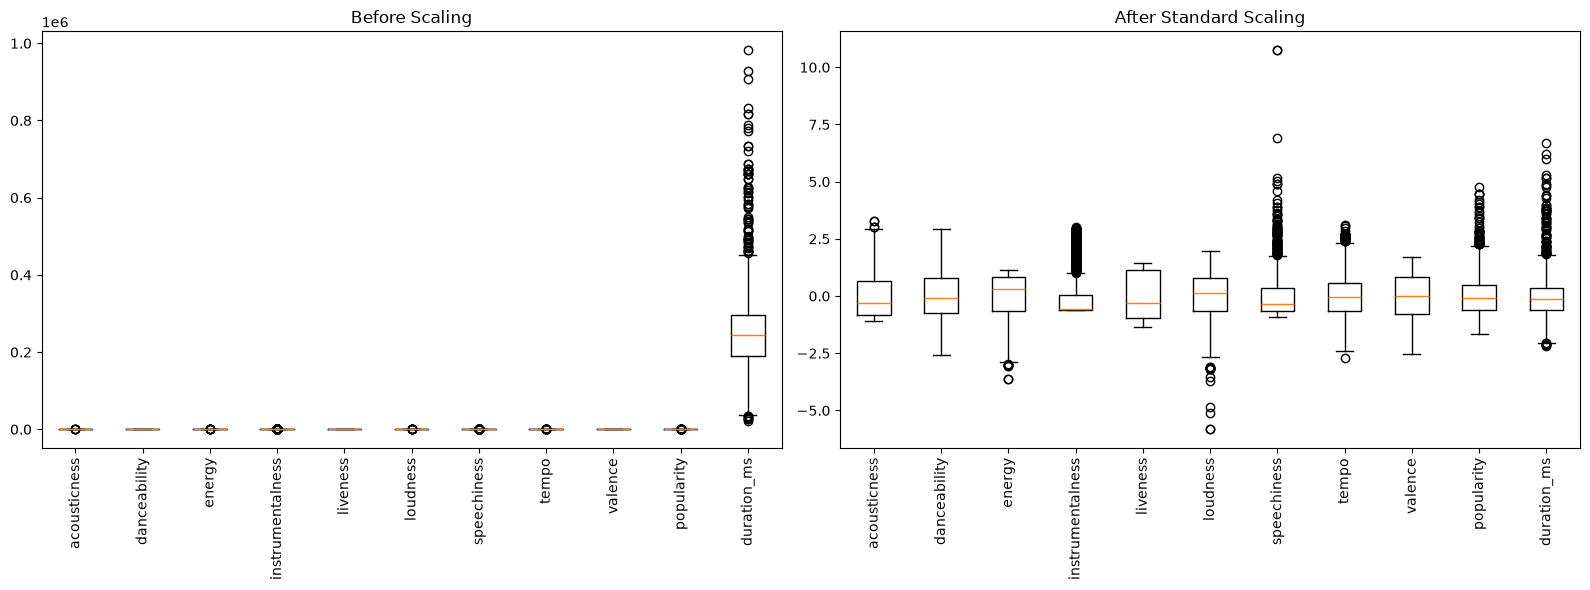

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Before scaling
axes[0].boxplot(
    X.values,
    tick_labels=X.columns.tolist()
)
axes[0].set_title("Before Scaling")
axes[0].tick_params(axis="x", rotation=90)

# After scaling
axes[1].boxplot(
    X_scaled.values, #type: ignore
    tick_labels=X_scaled.columns.tolist() #type: ignore
)
axes[1].set_title("After Standard Scaling")
axes[1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

In [52]:
X_final = X_scaled.copy()

print("Final clustering matrix shape:", X_final.shape)
print("Missing values:", X_final.isnull().sum().sum()) #type: ignore 

Final clustering matrix shape: (1610, 11)
Missing values: 0


In [53]:
print("=" * 60)
print("PHASE 2 - FEATURE PREPARATION VALIDATION")
print("=" * 60)

print("\nOriginal feature matrix:")
print("Shape:", X.shape)

print("\nScaled feature matrix:")
print("Shape:", X_final.shape)

print("\nMissing values:")
print(X_final.isnull().sum().sum()) #type: ignore

print("\nMean after scaling:")
print(X_final.mean().round(4))

print("\nStandard deviation after scaling:")
print(X_final.std().round(4))

print("\nFeatures used:")
print(feature_columns)

PHASE 2 - FEATURE PREPARATION VALIDATION

Original feature matrix:
Shape: (1610, 11)

Scaled feature matrix:
Shape: (1610, 11)

Missing values:
0

Mean after scaling:
acousticness       -0.0000
danceability       -0.0000
energy              0.0000
instrumentalness    0.0000
liveness            0.0000
loudness           -0.0000
speechiness        -0.0000
tempo               0.0000
valence             0.0000
popularity         -0.0000
duration_ms         0.0000
dtype: float64

Standard deviation after scaling:
acousticness       1.0003
danceability       1.0003
energy             1.0003
instrumentalness   1.0003
liveness           1.0003
loudness           1.0003
speechiness        1.0003
tempo              1.0003
valence            1.0003
popularity         1.0003
duration_ms        1.0003
dtype: float64

Features used:
['acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'popularity', 'duration_ms']


In [54]:
from sklearn.cluster import KMeans

inertias = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_final)
    inertias.append(kmeans.inertia_)

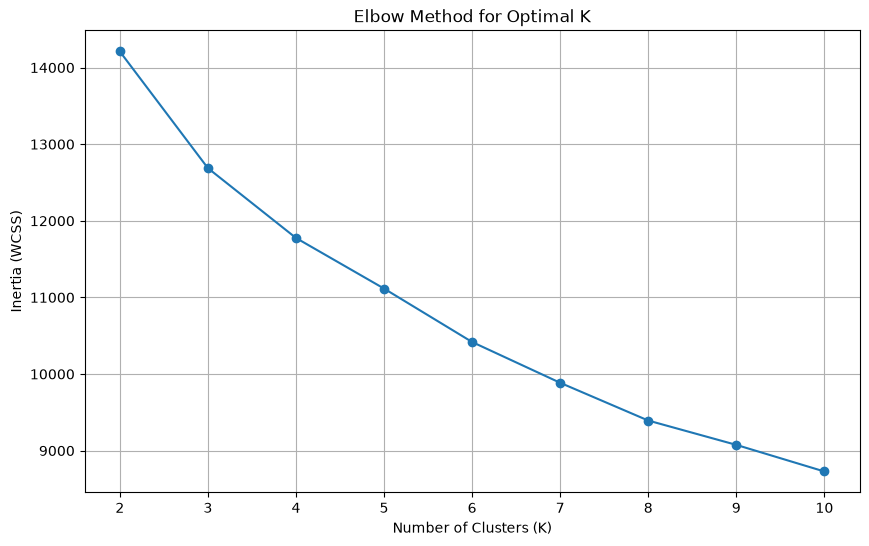

In [55]:
plt.figure(figsize=(10, 6))

plt.plot(
    list(K_range),
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method for Optimal K")

plt.xticks(list(K_range))
plt.grid(True)

plt.show()


In [56]:
elbow_results = pd.DataFrame({
    "K": list(K_range),
    "Inertia": inertias
})

display(elbow_results)


,K,Inertia
0,2,14209.9816
1,3,12687.4662
2,4,11776.0029
3,5,11115.3215
4,6,10417.8600
5,7,9885.4533
6,8,9392.6760
7,9,9074.9577
8,10,8727.6179


In [57]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(X_final)
    
    score = silhouette_score(
        X_final,
        cluster_labels
    )
    
    silhouette_scores.append(score)

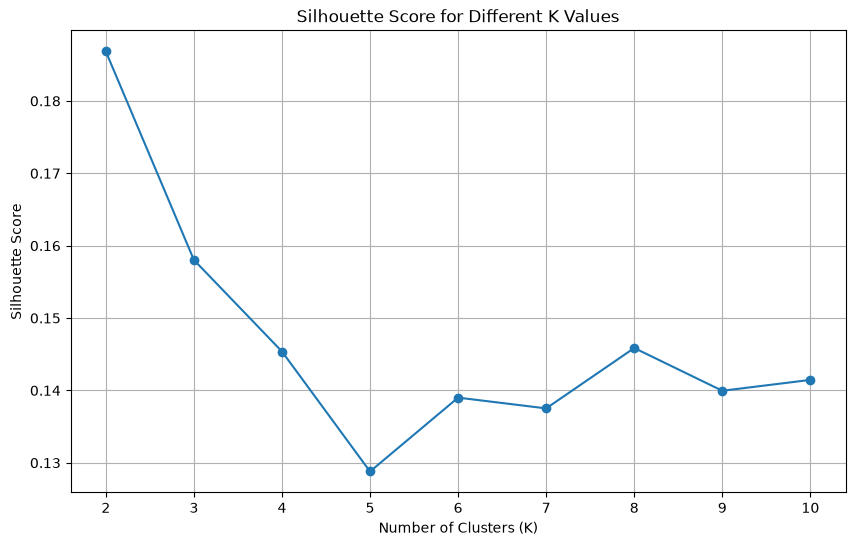

In [58]:
plt.figure(figsize=(10, 6))

plt.plot(
    list(K_range),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.xticks(list(K_range))
plt.grid(True)

plt.show()

In [59]:
silhouette_results = pd.DataFrame({
    "K": list(K_range),
    "Silhouette Score": silhouette_scores
})

display(silhouette_results)

,K,Silhouette Score
0,2,0.1868
1,3,0.1580
2,4,0.1454
3,5,0.1288
4,6,0.1390
5,7,0.1375
6,8,0.1459
7,9,0.1400
8,10,0.1415


In [60]:
best_silhouette_k = list(K_range)[
    np.argmax(silhouette_scores)
]

best_silhouette_score = max(silhouette_scores)

print("Best K:", best_silhouette_k)
print("Best Silhouette Score:", best_silhouette_score)

Best K: 2
Best Silhouette Score: 0.18683102447550132


In [61]:
from sklearn.metrics import calinski_harabasz_score

calinski_scores = []

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(X_final)
    
    score = calinski_harabasz_score(
        X_final,
        cluster_labels
    )
    
    calinski_scores.append(score)

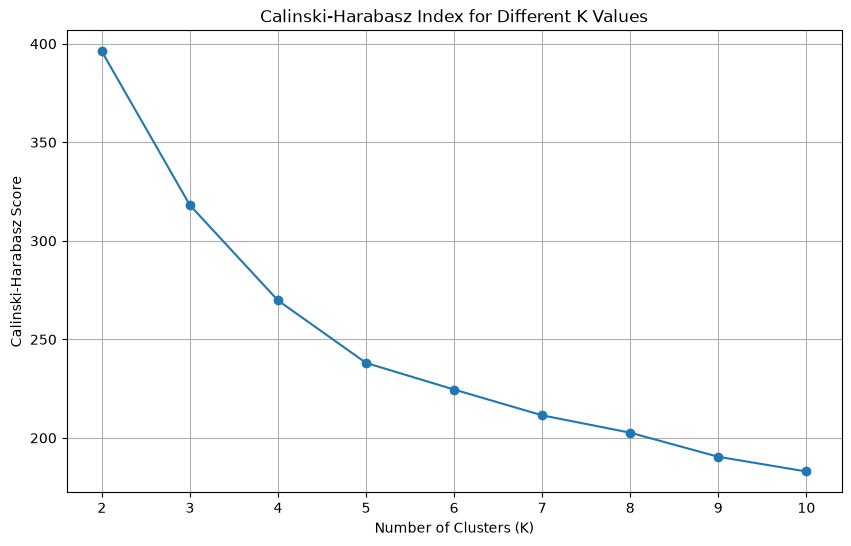

In [62]:
plt.figure(figsize=(10, 6))

plt.plot(
    list(K_range),
    calinski_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Calinski-Harabasz Score")
plt.title("Calinski-Harabasz Index for Different K Values")

plt.xticks(list(K_range))
plt.grid(True)

plt.show()

In [63]:
calinski_results = pd.DataFrame({
    "K": list(K_range),
    "Calinski-Harabasz Score": calinski_scores
})

display(calinski_results)

,K,Calinski-Harabasz Score
0,2,396.0617
1,3,318.0782
2,4,269.7576
3,5,238.0601
4,6,224.5489
5,7,211.4681
6,8,202.6557
7,9,190.4238
8,10,182.9672


In [64]:
best_calinski_k = list(K_range)[
    np.argmax(calinski_scores)
]

print("Best K:", best_calinski_k)
print(
    "Best Calinski-Harabasz Score:",
    max(calinski_scores)
)

Best K: 2
Best Calinski-Harabasz Score: 396.061705839354


In [65]:
from sklearn.metrics import davies_bouldin_score

davies_scores = []

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(X_final)
    
    score = davies_bouldin_score(
        X_final,
        cluster_labels
    )
    
    davies_scores.append(score)

    

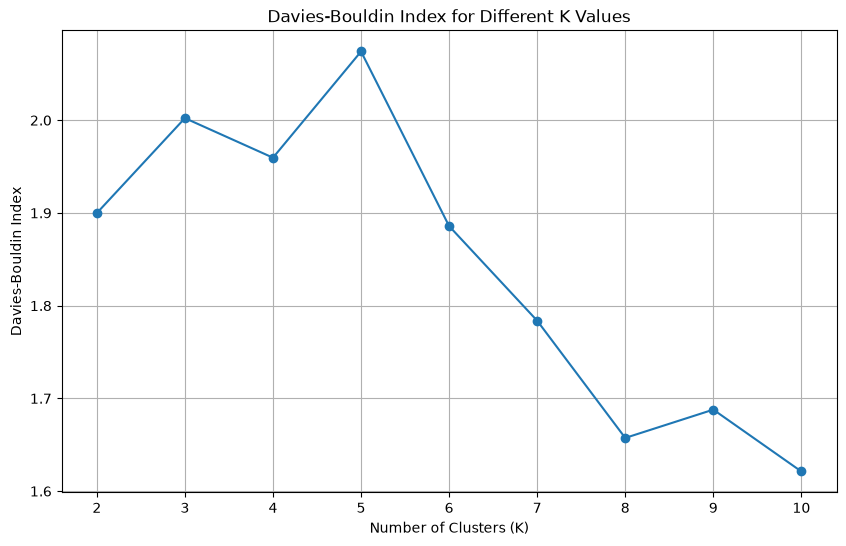

In [66]:
plt.figure(figsize=(10, 6))

plt.plot(
    list(K_range),
    davies_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Davies-Bouldin Index")
plt.title("Davies-Bouldin Index for Different K Values")

plt.xticks(list(K_range))
plt.grid(True)

plt.show()

In [67]:
davies_results = pd.DataFrame({
    "K": list(K_range),
    "Davies-Bouldin Index": davies_scores
})

display(davies_results)

,K,Davies-Bouldin Index
0,2,1.8999
1,3,2.0023
2,4,1.9596
3,5,2.0741
4,6,1.8858
5,7,1.7838
6,8,1.6574
7,9,1.6879
8,10,1.6212


In [68]:
best_davies_k = list(K_range)[
    np.argmin(davies_scores)
]

print("Best K:", best_davies_k)
print(
    "Best Davies-Bouldin Index:",
    min(davies_scores)
)

Best K: 10
Best Davies-Bouldin Index: 1.6211862187469588


In [69]:
cluster_evaluation = pd.DataFrame({
    "K": list(K_range),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores,
    "Calinski-Harabasz": calinski_scores,
    "Davies-Bouldin": davies_scores
})

display(cluster_evaluation)

,K,Inertia,Silhouette Score,Calinski-Harabasz,Davies-Bouldin
0,2,14209.9816,0.1868,396.0617,1.8999
1,3,12687.4662,0.1580,318.0782,2.0023
2,4,11776.0029,0.1454,269.7576,1.9596
3,5,11115.3215,0.1288,238.0601,2.0741
4,6,10417.8600,0.1390,224.5489,1.8858
5,7,9885.4533,0.1375,211.4681,1.7838
6,8,9392.6760,0.1459,202.6557,1.6574
7,9,9074.9577,0.1400,190.4238,1.6879
8,10,8727.6179,0.1415,182.9672,1.6212


In [70]:
from sklearn.cluster import KMeans

optimal_k = 2

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

df_clustered = df_clean.copy()
df_clustered["cluster"] = cluster_labels

print("K-Means Clustering Completed")
print(f"Number of clusters: {optimal_k}")
print(f"Cluster counts:")
print(df_clustered["cluster"].value_counts().sort_index())

display(
    df_clustered[
        ["name", "album", "track_number", "cluster"]
    ].head(20)
)

K-Means Clustering Completed
Number of clusters: 2
Cluster counts:
cluster
0    728
1    882
Name: count, dtype: int64


,name,album,track_number,cluster
0,Concert Intro Music - Live,Licked Live In NYC,1,0
1,Street Fighting Man - Live,Licked Live In NYC,2,0
2,Start Me Up - Live,Licked Live In NYC,3,0
3,If You Can't Rock Me - Live,Licked Live In NYC,4,0
4,Don’t Stop - Live,Licked Live In NYC,5,0
5,Monkey Man - Live,Licked Live In NYC,6,0
6,Angie - Live,Licked Live In NYC,7,0
7,Let It Bleed - Live,Licked Live In NYC,8,0
8,Midnight Rambler - Live,Licked Live In NYC,9,0
9,Tumbling Dice - Live,Licked Live In NYC,10,0


In [71]:
features = [
    "acousticness",
    "danceability",
    "energy",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "tempo",
    "valence",
    "popularity",
    "duration_ms"
]

cluster_profile = df_clustered.groupby("cluster")[
    features
].mean()

display(cluster_profile)

,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
cluster,,,,,,,,,,,
0,0.1949,0.3715,0.9103,0.1616,0.7885,-5.5146,0.0969,134.4537,0.4804,17.9176,292074.1003
1,0.2964,0.5492,0.6950,0.1663,0.2468,-8.1742,0.0469,119.1721,0.6662,23.1576,229394.3322


In [72]:
from sklearn.cluster import KMeans

# Optimal number of clusters selected from Phase 3 evaluation
optimal_k = 2

# Initialize K-Means
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Train model and generate cluster labels
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to a copy of the cleaned dataset
df_clustered = df_clean.copy()
df_clustered["cluster"] = cluster_labels

print("K-Means Clustering Completed")
print(f"Number of clusters: {optimal_k}")

K-Means Clustering Completed
Number of clusters: 2


In [73]:
cluster_counts = (
    df_clustered["cluster"]
    .value_counts()
    .sort_index()
)

print("Cluster Distribution:")
print(cluster_counts)

Cluster Distribution:
cluster
0    728
1    882
Name: count, dtype: int64


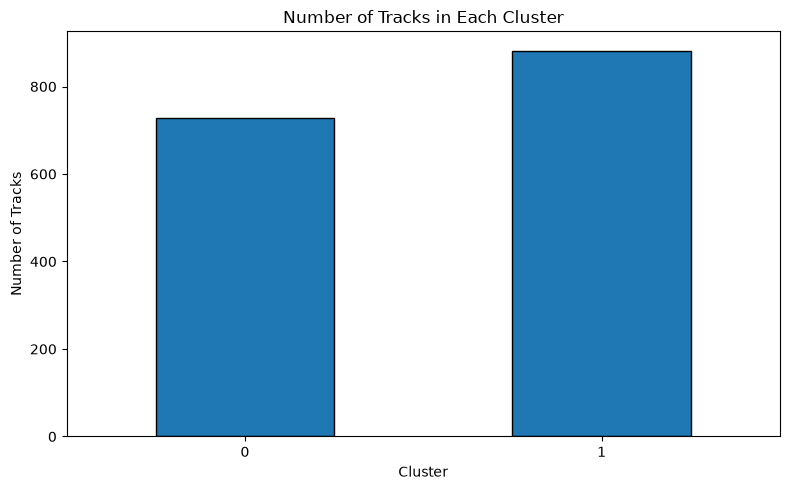

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

cluster_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Number of Tracks in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [75]:
display(
    df_clustered[
        ["name", "album", "track_number", "popularity", "cluster"]
    ].head(20)
)

,name,album,track_number,popularity,cluster
0,Concert Intro Music - Live,Licked Live In NYC,1,33,0
1,Street Fighting Man - Live,Licked Live In NYC,2,34,0
2,Start Me Up - Live,Licked Live In NYC,3,34,0
3,If You Can't Rock Me - Live,Licked Live In NYC,4,32,0
4,Don’t Stop - Live,Licked Live In NYC,5,32,0
5,Monkey Man - Live,Licked Live In NYC,6,31,0
6,Angie - Live,Licked Live In NYC,7,31,0
7,Let It Bleed - Live,Licked Live In NYC,8,30,0
8,Midnight Rambler - Live,Licked Live In NYC,9,30,0
9,Tumbling Dice - Live,Licked Live In NYC,10,29,0


In [76]:
cluster_profile = (
    df_clustered
    .groupby("cluster")[features]
    .mean()
)

display(cluster_profile)

,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
cluster,,,,,,,,,,,
0,0.1949,0.3715,0.9103,0.1616,0.7885,-5.5146,0.0969,134.4537,0.4804,17.9176,292074.1003
1,0.2964,0.5492,0.6950,0.1663,0.2468,-8.1742,0.0469,119.1721,0.6662,23.1576,229394.3322


In [77]:
import pandas as pd

cluster_profile_scaled = pd.DataFrame(
    X_scaled,
    columns=features
)

cluster_profile_scaled["cluster"] = cluster_labels

cluster_profile_scaled = (
    cluster_profile_scaled
    .groupby("cluster")
    .mean()
)

display(cluster_profile_scaled)

,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
cluster,,,,,,,,,,,
0,-0.2446,-0.6869,0.6561,-0.0093,0.8503,0.4868,0.5310,0.2865,-0.4401,-0.2311,0.3171
1,0.2019,0.5670,-0.5415,0.0077,-0.7018,-0.4018,-0.4382,-0.2364,0.3633,0.1907,-0.2617


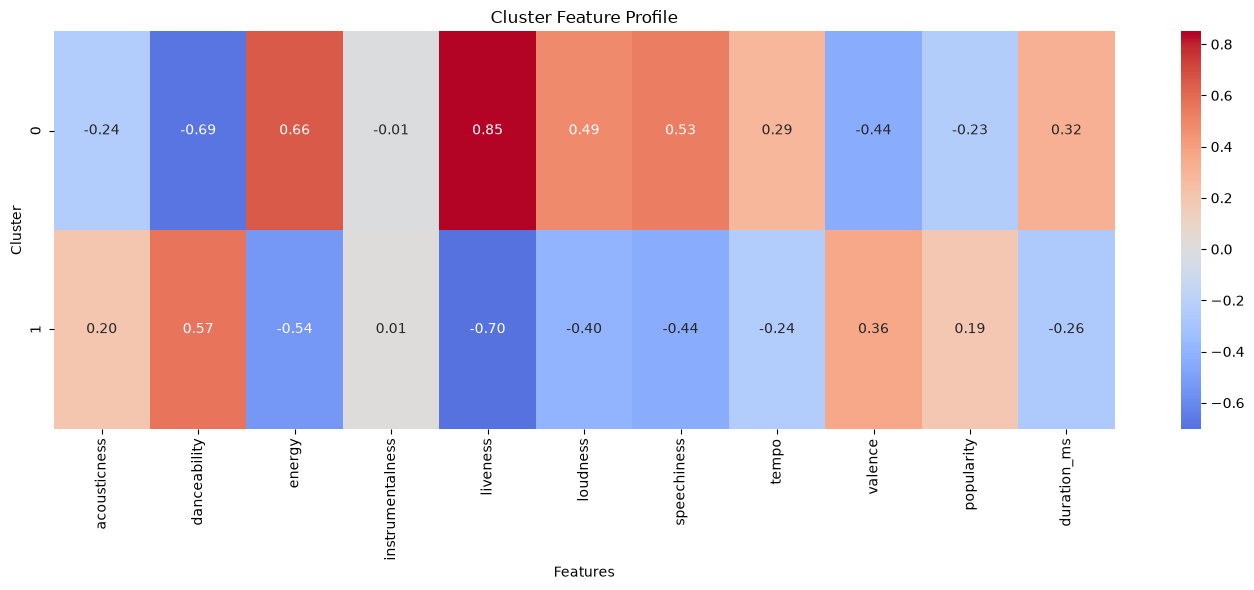

In [78]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

sns.heatmap(
    cluster_profile_scaled,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Cluster Feature Profile")
plt.xlabel("Features")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

In [79]:
cluster_summary = (
    df_clustered
    .groupby("cluster")[features]
    .agg(["mean", "median", "std"])
)

display(cluster_summary)

acousticness               danceability               energy         \
                mean median    std         mean median    std   mean median   
cluster                                                                       
0             0.1949 0.1390 0.1886       0.3715 0.3720 0.0984 0.9103 0.9430   
1             0.2964 0.2240 0.2458       0.5492 0.5580 0.1201 0.6950 0.7100   

               instrumentalness               liveness               loudness  \
           std             mean median    std     mean median    std     mean   
cluster                                                                         
0       0.0890           0.1616 0.0134 0.2739   0.7885 0.9055 0.2435  -5.5146   
1       0.1777           0.1663 0.0140 0.2783   0.2468 0.1730 0.2020  -8.1742   

                       speechiness                  tempo                   \
         median    std        mean median    std     mean   median     std   
cluster                                                                      
0       -5.2405 2.0087      0.0969 0.0829 0.0615 134.4537 136.1050 29.6278   
1       -8.2930 3.1368      0.0469 0.0396 0.0247 119.1721 116.7310 27.0314   

        valence               popularity                 duration_ms  \
           mean median    std       mean  median     std        mean   
cluster                                                                
0        0.4804 0.4725 0.1926    17.9176 18.0000  8.2789 292074.1003   
1        0.6662 0.7210 0.2268    23.1576 23.0000 14.5961 229394.3322   

                                 
             median         std  
cluster                          
0       264379.5000 126792.9271  
1       218386.0000  79933.4319

In [81]:
print("DataFrames containing 'cluster':")
print("=" * 60)

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if "cluster" in obj.columns:
            print(f"\n{name}")
            print(f"Shape: {obj.shape}")
            print(f"Columns: {obj.columns.tolist()}")

DataFrames containing 'cluster':

df_clustered
Shape: (1610, 18)
Columns: ['name', 'album', 'release_date', 'track_number', 'id', 'uri', 'acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'popularity', 'duration_ms', 'cluster']


In [82]:
# Create a copy of the cleaned dataset
df_clustered = df_clean.copy()

# Add cluster assignments generated by K-Means
df_clustered["cluster"] = kmeans.labels_

print("Clustered dataset shape:", df_clustered.shape)
print("\nCluster distribution:")
print(df_clustered["cluster"].value_counts().sort_index())

display(
    df_clustered[
        ["name", "album", "track_number", "popularity", "cluster"]
    ].head(20)
)

Clustered dataset shape: (1610, 18)

Cluster distribution:
cluster
0    728
1    882
Name: count, dtype: int64


,name,album,track_number,popularity,cluster
0,Concert Intro Music - Live,Licked Live In NYC,1,33,0
1,Street Fighting Man - Live,Licked Live In NYC,2,34,0
2,Start Me Up - Live,Licked Live In NYC,3,34,0
3,If You Can't Rock Me - Live,Licked Live In NYC,4,32,0
4,Don’t Stop - Live,Licked Live In NYC,5,32,0
5,Monkey Man - Live,Licked Live In NYC,6,31,0
6,Angie - Live,Licked Live In NYC,7,31,0
7,Let It Bleed - Live,Licked Live In NYC,8,30,0
8,Midnight Rambler - Live,Licked Live In NYC,9,30,0
9,Tumbling Dice - Live,Licked Live In NYC,10,29,0


In [83]:
cluster_labels = {
    0: "High-Energy / Live / Intense",
    1: "Danceable / Positive / Balanced"
}

df_clustered["cluster_label"] = (
    df_clustered["cluster"].map(cluster_labels)
)

display(
    df_clustered[
        [
            "name",
            "album",
            "cluster",
            "cluster_label"
        ]
    ].head(20)
)

,name,album,cluster,cluster_label
0,Concert Intro Music - Live,Licked Live In NYC,0,High-Energy / Live / Intense
1,Street Fighting Man - Live,Licked Live In NYC,0,High-Energy / Live / Intense
2,Start Me Up - Live,Licked Live In NYC,0,High-Energy / Live / Intense
3,If You Can't Rock Me - Live,Licked Live In NYC,0,High-Energy / Live / Intense
4,Don’t Stop - Live,Licked Live In NYC,0,High-Energy / Live / Intense
5,Monkey Man - Live,Licked Live In NYC,0,High-Energy / Live / Intense
6,Angie - Live,Licked Live In NYC,0,High-Energy / Live / Intense
7,Let It Bleed - Live,Licked Live In NYC,0,High-Energy / Live / Intense
8,Midnight Rambler - Live,Licked Live In NYC,0,High-Energy / Live / Intense
9,Tumbling Dice - Live,Licked Live In NYC,0,High-Energy / Live / Intense


In [85]:
print("DataFrames containing 'cluster':")
print("=" * 60)

for var_name, var_value in list(globals().items()):
    if isinstance(var_value, pd.DataFrame):
        if "cluster" in var_value.columns:
            print(f"\nDataFrame: {var_name}")
            print(f"Shape: {var_value.shape}")
            print(f"Columns: {var_value.columns.tolist()}")

DataFrames containing 'cluster':

DataFrame: df_clustered
Shape: (1610, 19)
Columns: ['name', 'album', 'release_date', 'track_number', 'id', 'uri', 'acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'popularity', 'duration_ms', 'cluster', 'cluster_label']


In [90]:
print("kmeans exists:", "kmeans" in globals())

if "kmeans" in globals():
    print("Number of cluster labels:", len(kmeans.labels_))
    print("Cluster centers shape:", kmeans.cluster_centers_.shape)
    print("Cluster distribution:")
    print(pd.Series(kmeans.labels_).value_counts().sort_index())

kmeans exists: True
Number of cluster labels: 1610
Cluster centers shape: (2, 11)
Cluster distribution:
0    728
1    882
Name: count, dtype: int64


In [87]:
df_phase4 = df_clean.copy()

df_phase4["cluster"] = kmeans.labels_

print("Phase 4 dataset shape:", df_phase4.shape)

print("\nCluster distribution:")
print(
    df_phase4["cluster"]
    .value_counts()
    .sort_index()
)

Phase 4 dataset shape: (1610, 18)

Cluster distribution:
cluster
0    728
1    882
Name: count, dtype: int64


In [88]:
cluster_labels = {
    0: "High-Energy / Live / Intense",
    1: "Danceable / Positive / Balanced"
}

df_phase4["cluster_label"] = (
    df_phase4["cluster"]
    .map(cluster_labels)
)

display(
    df_phase4[
        [
            "name",
            "album",
            "track_number",
            "cluster",
            "cluster_label"
        ]
    ].head(20)
)

,name,album,track_number,cluster,cluster_label
0,Concert Intro Music - Live,Licked Live In NYC,1,0,High-Energy / Live / Intense
1,Street Fighting Man - Live,Licked Live In NYC,2,0,High-Energy / Live / Intense
2,Start Me Up - Live,Licked Live In NYC,3,0,High-Energy / Live / Intense
3,If You Can't Rock Me - Live,Licked Live In NYC,4,0,High-Energy / Live / Intense
4,Don’t Stop - Live,Licked Live In NYC,5,0,High-Energy / Live / Intense
5,Monkey Man - Live,Licked Live In NYC,6,0,High-Energy / Live / Intense
6,Angie - Live,Licked Live In NYC,7,0,High-Energy / Live / Intense
7,Let It Bleed - Live,Licked Live In NYC,8,0,High-Energy / Live / Intense
8,Midnight Rambler - Live,Licked Live In NYC,9,0,High-Energy / Live / Intense
9,Tumbling Dice - Live,Licked Live In NYC,10,0,High-Energy / Live / Intense


In [93]:
print("\nDataset Shape:")
print(df_phase4.shape)

print("\nCluster Distribution:")
print(
    df_phase4["cluster"]
    .value_counts()
    .sort_index()
)

print("\nCluster → Label Mapping:")
display(
    df_phase4[
        ["cluster", "cluster_label"]
    ]
    .drop_duplicates()
    .sort_values("cluster")
)

print("\nMissing Cluster Values:")
print(df_phase4["cluster"].isna().sum())

print("\nMissing Cluster Labels:")
print(df_phase4["cluster_label"].isna().sum())


Dataset Shape:
(1610, 19)

Cluster Distribution:
cluster
0    728
1    882
Name: count, dtype: int64

Cluster → Label Mapping:


,cluster,cluster_label
0,0,High-Energy / Live / Intense
23,1,Danceable / Positive / Balanced



Missing Cluster Values:
0

Missing Cluster Labels:
0


In [95]:
df_clustered = df_clean.copy()

df_clustered["cluster"] = kmeans.labels_

cluster_labels = {
    0: "High-Energy / Live / Intense",
    1: "Danceable / Positive / Balanced"
}

df_clustered["cluster_label"] = df_clustered["cluster"].map(cluster_labels)

print("\nDataset shape:")
print(df_clustered.shape)

print("\nColumns:")
print(df_clustered.columns.tolist())

print("\nCluster distribution:")
print(df_clustered["cluster"].value_counts().sort_index())

print("\nMissing cluster labels:")
print(df_clustered["cluster_label"].isna().sum())

display(
    df_clustered[
        ["name", "album", "cluster", "cluster_label"]
    ].head(20)
)


Dataset shape:
(1610, 19)

Columns:
['name', 'album', 'release_date', 'track_number', 'id', 'uri', 'acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'popularity', 'duration_ms', 'cluster', 'cluster_label']

Cluster distribution:
cluster
0    728
1    882
Name: count, dtype: int64

Missing cluster labels:
0


,name,album,cluster,cluster_label
0,Concert Intro Music - Live,Licked Live In NYC,0,High-Energy / Live / Intense
1,Street Fighting Man - Live,Licked Live In NYC,0,High-Energy / Live / Intense
2,Start Me Up - Live,Licked Live In NYC,0,High-Energy / Live / Intense
3,If You Can't Rock Me - Live,Licked Live In NYC,0,High-Energy / Live / Intense
4,Don’t Stop - Live,Licked Live In NYC,0,High-Energy / Live / Intense
5,Monkey Man - Live,Licked Live In NYC,0,High-Energy / Live / Intense
6,Angie - Live,Licked Live In NYC,0,High-Energy / Live / Intense
7,Let It Bleed - Live,Licked Live In NYC,0,High-Energy / Live / Intense
8,Midnight Rambler - Live,Licked Live In NYC,0,High-Energy / Live / Intense
9,Tumbling Dice - Live,Licked Live In NYC,0,High-Energy / Live / Intense


In [96]:
cluster_summary = (
    df_clustered
    .groupby(["cluster", "cluster_label"])
    .size()
    .reset_index(name="track_count")
)

cluster_summary["percentage"] = (
    cluster_summary["track_count"]
    / len(df_clustered)
    * 100
)

display(cluster_summary)

,cluster,cluster_label,track_count,percentage
0,0,High-Energy / Live / Intense,728,45.2174
1,1,Danceable / Positive / Balanced,882,54.7826


In [97]:
print("\nCluster IDs:")
print(sorted(df_clustered["cluster"].unique()))

print("\nCluster labels:")
print(df_clustered["cluster_label"].unique())

print("\nMissing cluster labels:")
print(df_clustered["cluster_label"].isna().sum())

print("\nCluster-label cross-tabulation:")
print(
    pd.crosstab(
        df_clustered["cluster"],
        df_clustered["cluster_label"]
    )
)


Cluster IDs:
[np.int32(0), np.int32(1)]

Cluster labels:
<StringArray>
['High-Energy / Live / Intense', 'Danceable / Positive / Balanced']
Length: 2, dtype: str

Missing cluster labels:
0

Cluster-label cross-tabulation:
cluster_label  Danceable / Positive / Balanced  High-Energy / Live / Intense
cluster                                                                     
0                                            0                           728
1                                          882                             0


In [98]:
expected_distribution = {
    0: 728,
    1: 882
}

actual_distribution = (
    df_clustered["cluster"]
    .value_counts()
    .sort_index()
    .to_dict()
)

print("Expected distribution:")
print(expected_distribution)

print("\nActual distribution:")
print(actual_distribution)

if actual_distribution == expected_distribution:
    print("\n✓ Cluster distribution validated successfully.")
else:
    print("\n⚠ Cluster distribution does not match expected values.")

Expected distribution:
{0: 728, 1: 882}

Actual distribution:
{0: 728, 1: 882}

✓ Cluster distribution validated successfully.


In [99]:
phase4_summary = pd.DataFrame({
    "Metric": [
        "Total Tracks",
        "Number of Clusters",
        "Cluster 0 Tracks",
        "Cluster 1 Tracks",
        "Cluster 0 Percentage",
        "Cluster 1 Percentage",
        "Missing Cluster Labels"
    ],
    "Value": [
        len(df_clustered),
        df_clustered["cluster"].nunique(),
        (df_clustered["cluster"] == 0).sum(),
        (df_clustered["cluster"] == 1).sum(),
        f"{(df_clustered['cluster'] == 0).mean() * 100:.2f}%",
        f"{(df_clustered['cluster'] == 1).mean() * 100:.2f}%",
        df_clustered["cluster_label"].isna().sum()
    ]
})

display(phase4_summary)

,Metric,Value
0,Total Tracks,1610
1,Number of Clusters,2
2,Cluster 0 Tracks,728
3,Cluster 1 Tracks,882
4,Cluster 0 Percentage,45.22%
5,Cluster 1 Percentage,54.78%
6,Missing Cluster Labels,0


In [100]:
cluster_profile = (
    df_clustered
    .groupby(["cluster", "cluster_label"])[X.columns.tolist()]
    .mean()
    .round(4)
)

display(cluster_profile)

,,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
cluster,cluster_label,,,,,,,,,,,
0,High-Energy / Live / Intense,0.1949,0.3715,0.9103,0.1616,0.7885,-5.5146,0.0969,134.4537,0.4804,17.9176,292074.1003
1,Danceable / Positive / Balanced,0.2964,0.5492,0.6950,0.1663,0.2468,-8.1742,0.0469,119.1721,0.6662,23.1576,229394.3322


In [101]:
cluster_centers_scaled = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X.columns
)

cluster_centers_scaled.index.name = "cluster"

cluster_centers_scaled["cluster_label"] = (
    cluster_centers_scaled.index.map(cluster_labels)
)

display(cluster_centers_scaled.round(4))

,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms,cluster_label
cluster,,,,,,,,,,,,
0,-0.2446,-0.6869,0.6561,-0.0093,0.8503,0.4868,0.5310,0.2865,-0.4401,-0.2311,0.3171,High-Energy / Live / Intense
1,0.2019,0.5670,-0.5415,0.0077,-0.7018,-0.4018,-0.4382,-0.2364,0.3633,0.1907,-0.2617,Danceable / Positive / Balanced


In [ ]:
feature_difference = (
    cluster_centers_scaled.drop(columns="cluster_label")
    .loc[0]
    .subtract(
        cluster_centers_scaled.drop(columns="cluster_label").loc[1]
    )
    .sort_values(key=abs, ascending=False)
) #type: ignore

print("Feature differences between Cluster 0 and Cluster 1:")
display(feature_difference.to_frame("Difference"))

Feature differences between Cluster 0 and Cluster 1:


,Difference
liveness,1.5521
danceability,-1.2539
energy,1.1976
speechiness,0.9692
loudness,0.8886
valence,-0.8034
duration_ms,0.5788
tempo,0.5229
acousticness,-0.4464
popularity,-0.4218


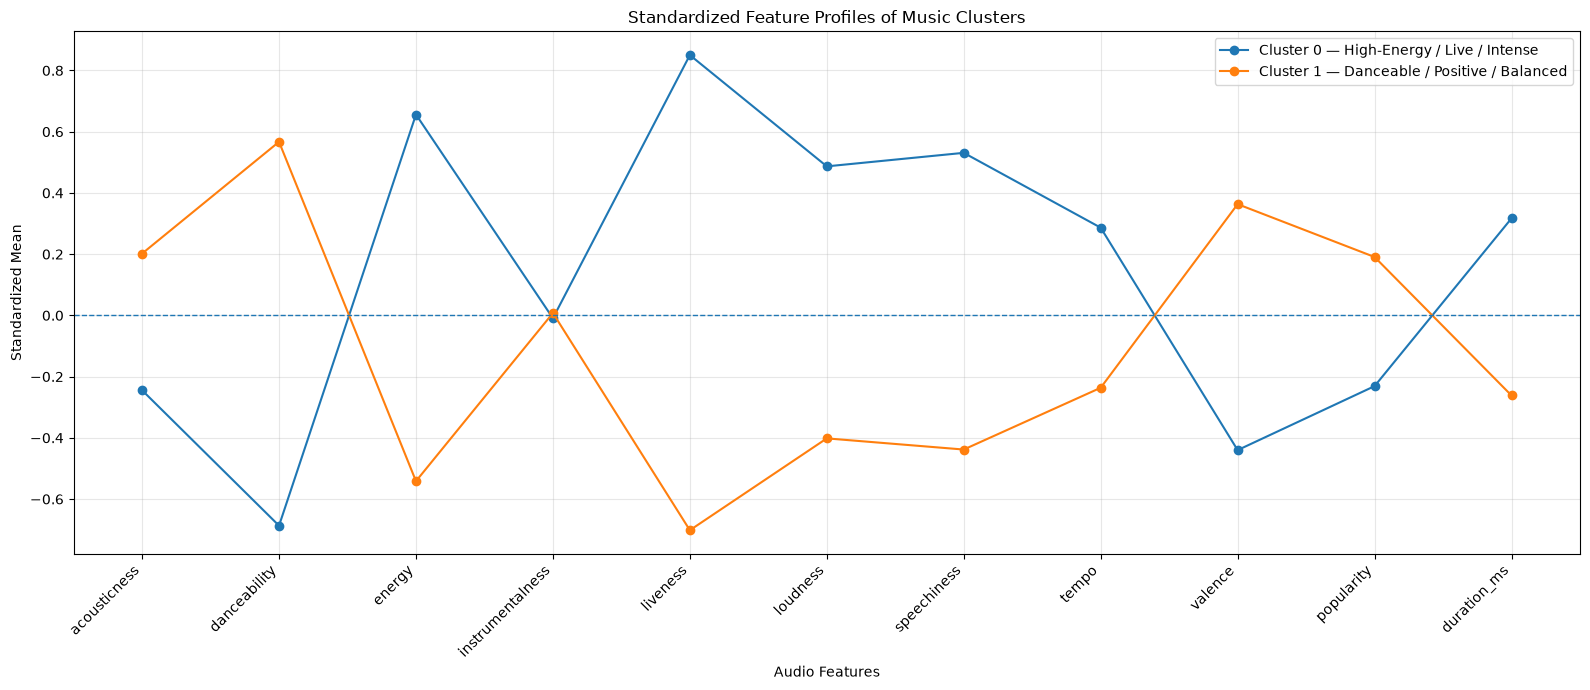

In [103]:
features = X.columns.tolist()

plt.figure(figsize=(16, 7))

plt.plot(
    features,
    cluster_centers_scaled.loc[0, features],
    marker="o",
    label="Cluster 0 — High-Energy / Live / Intense"
)

plt.plot(
    features,
    cluster_centers_scaled.loc[1, features],
    marker="o",
    label="Cluster 1 — Danceable / Positive / Balanced"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Standardized Feature Profiles of Music Clusters")
plt.xlabel("Audio Features")
plt.ylabel("Standardized Mean")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

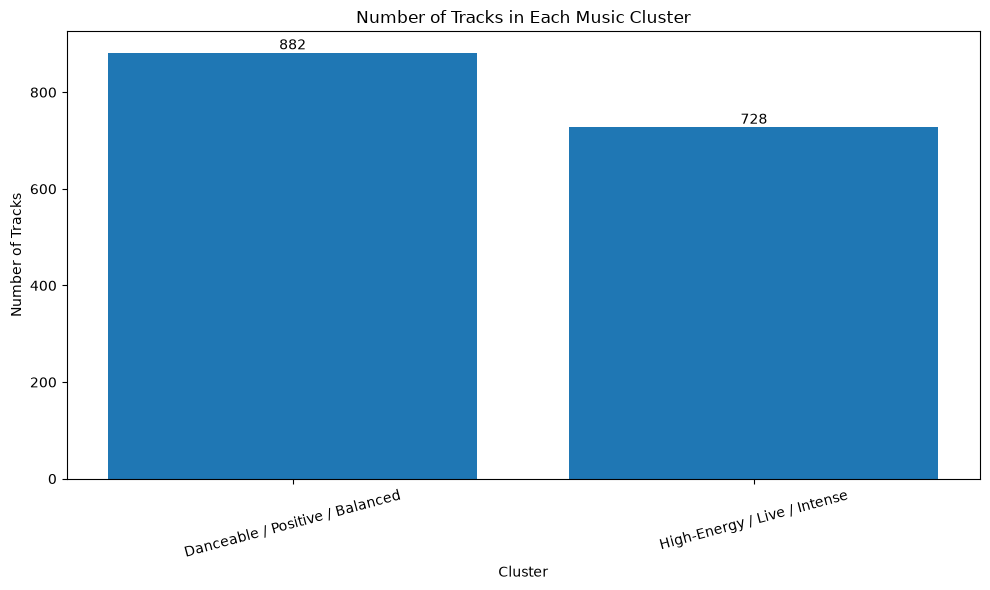

In [ ]:
cluster_counts = (
    df_clustered["cluster_label"]
    .value_counts()
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    cluster_counts.index,
    cluster_counts.values #type: ignore
)

plt.title("Number of Tracks in Each Music Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=15)

for bar, value in zip(bars, cluster_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [105]:
popularity_by_cluster = (
    df_clustered
    .groupby(["cluster", "cluster_label"])["popularity"]
    .agg(["mean", "median", "min", "max", "std"])
    .round(2)
)

display(popularity_by_cluster)

,,mean,median,min,max,std
cluster,cluster_label,,,,,
0,High-Energy / Live / Intense,17.9200,18.0000,0,50,8.2800
1,Danceable / Positive / Balanced,23.1600,23.0000,0,80,14.6000


In [106]:
df_clustered["duration_min"] = (
    df_clustered["duration_ms"] / 60000
)

duration_by_cluster = (
    df_clustered
    .groupby(["cluster", "cluster_label"])["duration_min"]
    .agg(["mean", "median", "min", "max", "std"])
    .round(2)
)

display(duration_by_cluster)

,,mean,median,min,max,std
cluster,cluster_label,,,,,
0,High-Energy / Live / Intense,4.8700,4.4100,0.3500,16.3600,2.1100
1,Danceable / Positive / Balanced,3.8200,3.6400,0.4600,11.2200,1.3300


In [107]:
for cluster_id in sorted(df_clustered["cluster"].unique()):

    label = cluster_labels[cluster_id]

    print("\n" + "=" * 70)
    print(f"CLUSTER {cluster_id}: {label}")
    print("=" * 70)

    display(
        df_clustered[
            df_clustered["cluster"] == cluster_id
        ][
            [
                "name",
                "album",
                "popularity",
                "energy",
                "danceability",
                "liveness",
                "valence",
                "tempo"
            ]
        ]
        .sort_values("popularity", ascending=False)
        .head(10)
    )


CLUSTER 0: High-Energy / Live / Intense


,name,album,popularity,energy,danceability,liveness,valence,tempo
1468,The Last Time - Mono Version,Out Of Our Heads,50,0.9200,0.3270,0.7740,0.4390,167.9720
1121,Sway - 2009 Mix,Sticky Fingers (Remastered),46,0.8950,0.3300,0.4080,0.5400,144.9450
774,Mixed Emotions,Steel Wheels (Remastered 2009),45,0.9560,0.4930,0.8300,0.8310,137.0910
1565,Time Is On My Side - Mono Version / Organ Intro,12 X 5,44,0.8300,0.2290,0.0712,0.4230,216.3040
697,Like A Rolling Stone - Live / Remastered 2009,Stripped,43,0.9430,0.2140,0.9530,0.3330,205.5260
1053,All Down The Line,Exile On Main Street (2010 Re-Mastered),42,0.9730,0.5190,0.7840,0.8220,140.2210
829,Undercover (Of The Night) - Remastered 2009,Undercover (2009 Re-Mastered),42,0.9730,0.6030,0.4720,0.4080,122.7560
445,Hate To See You Go,Blue & Lonesome,41,0.8280,0.4180,0.1460,0.3760,184.4360
808,One Hit (To The Body) - Remastered,Dirty Work (Remastered 2009),39,0.9640,0.5860,0.6880,0.6100,138.2930
663,Start Me Up - Live Licks Tour - 2009 Re-Master...,Live Licks,37,0.9860,0.4550,0.9800,0.5180,130.3010



CLUSTER 1: Danceable / Positive / Balanced


,name,album,popularity,energy,danceability,liveness,valence,tempo
1403,"Paint It, Black",Aftermath,80,0.7950,0.4640,0.3990,0.6120,158.6910
862,Start Me Up - Remastered 2009,Tattoo You (2009 Re-Mastered),76,0.9320,0.6310,0.0918,0.9710,122.4290
1472,(I Can't Get No) Satisfaction - Mono Version,Out Of Our Heads,76,0.8630,0.7230,0.1280,0.9310,136.3020
1248,Gimme Shelter,Let It Bleed,76,0.6300,0.6340,0.1700,0.4890,118.6280
1257,Sympathy For The Devil - 50th Anniversary Edition,Beggars Banquet (50th Anniversary Edition),73,0.6680,0.7020,0.0588,0.5610,116.0630
901,Beast Of Burden - Remastered 1994,Some Girls,72,0.8780,0.7830,0.0426,0.8850,100.6260
1023,Angie,Goats Head Soup (Remastered 2009),71,0.5540,0.4290,0.1050,0.4070,136.3020
893,Miss You - Remastered,Some Girls,69,0.7100,0.7950,0.3440,0.8450,109.6890
1122,Wild Horses - 2009 Mix,Sticky Fingers (Remastered),69,0.3890,0.4320,0.0788,0.1580,139.5060
1256,You Can't Always Get What You Want,Let It Bleed,67,0.6200,0.3200,0.2530,0.4720,86.3270


In [108]:
phase5_summary = []

for cluster_id in sorted(df_clustered["cluster"].unique()):

    cluster_data = df_clustered[
        df_clustered["cluster"] == cluster_id
    ]

    phase5_summary.append({
        "Cluster": cluster_id,
        "Label": cluster_labels[cluster_id],
        "Tracks": len(cluster_data),
        "Percentage": round(
            len(cluster_data) / len(df_clustered) * 100,
            2
        ),
        "Mean Energy": round(
            cluster_data["energy"].mean(), 3
        ),
        "Mean Danceability": round(
            cluster_data["danceability"].mean(), 3
        ),
        "Mean Liveness": round(
            cluster_data["liveness"].mean(), 3
        ),
        "Mean Valence": round(
            cluster_data["valence"].mean(), 3
        ),
        "Mean Popularity": round(
            cluster_data["popularity"].mean(), 2
        ),
        "Mean Duration (min)": round(
            cluster_data["duration_min"].mean(), 2
        )
    })

phase5_summary = pd.DataFrame(phase5_summary)

display(phase5_summary)

,Cluster,Label,Tracks,Percentage,Mean Energy,Mean Danceability,Mean Liveness,Mean Valence,Mean Popularity,Mean Duration (min)
0,0,High-Energy / Live / Intense,728,45.2200,0.9100,0.3720,0.7880,0.4800,17.9200,4.8700
1,1,Danceable / Positive / Balanced,882,54.7800,0.6950,0.5490,0.2470,0.6660,23.1600,3.8200


In [110]:
print("\nCluster column exists:")
print("cluster" in df_clustered.columns)

print("\nNumber of tracks:")
print(len(df_clustered))

print("\nUnique clusters:")
print(sorted(df_clustered["cluster"].unique()))

print("\nCluster distribution:")
print(df_clustered["cluster"].value_counts().sort_index())


print("\nMissing cluster assignments:")
print(df_clustered["cluster"].isna().sum())

print("\nDuplicate Spotify IDs:")
print(df_clustered["id"].duplicated().sum())

print("\nCluster labels:")
print(
    df_clustered[
        ["cluster", "cluster_label"]
    ].drop_duplicates().sort_values("cluster")
)

validation_passed = (
    len(df_clustered) == 1610
    and df_clustered["cluster"].notna().all()
    and df_clustered["id"].duplicated().sum() == 0
    and df_clustered["cluster_label"].notna().all()
)



Cluster column exists:
True

Number of tracks:
1610

Unique clusters:
[np.int32(0), np.int32(1)]

Cluster distribution:
cluster
0    728
1    882
Name: count, dtype: int64

Missing cluster assignments:
0

Duplicate Spotify IDs:
0

Cluster labels:
    cluster                    cluster_label
0         0     High-Energy / Live / Intense
23        1  Danceable / Positive / Balanced


In [111]:
cluster_features = [
    "acousticness",
    "danceability",
    "energy",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "tempo",
    "valence",
    "popularity",
    "duration_min"
]

cluster_stats = (
    df_clustered
    .groupby(["cluster", "cluster_label"])[cluster_features]
    .agg(["mean", "median", "std"])
    .round(3)
)

display(cluster_stats)

acousticness                \
                                                mean median    std   
cluster cluster_label                                                
0       High-Energy / Live / Intense          0.1950 0.1390 0.1890   
1       Danceable / Positive / Balanced       0.2960 0.2240 0.2460   

                                        danceability               energy  \
                                                mean median    std   mean   
cluster cluster_label                                                       
0       High-Energy / Live / Intense          0.3720 0.3720 0.0980 0.9100   
1       Danceable / Positive / Balanced       0.5490 0.5580 0.1200 0.6950   

                                                      instrumentalness         \
                                        median    std             mean median   
cluster cluster_label                                                           
0       High-Energy / Live / Intense    0.9430 0.0890           0.1620 0.0130   
1       Danceable / Positive / Balanced 0.7100 0.1780           0.1660 0.0140   

                                               liveness                \
                                           std     mean median    std   
cluster cluster_label                                                   
0       High-Energy / Live / Intense    0.2740   0.7880 0.9060 0.2440   
1       Danceable / Positive / Balanced 0.2780   0.2470 0.1730 0.2020   

                                        loudness                speechiness  \
                                            mean  median    std        mean   
cluster cluster_label                                                         
0       High-Energy / Live / Intense     -5.5150 -5.2400 2.0090      0.0970   
1       Danceable / Positive / Balanced  -8.1740 -8.2930 3.1370      0.0470   

                                                         tempo           \
                                        median    std     mean   median   
cluster cluster_label                                                     
0       High-Energy / Live / Intense    0.0830 0.0620 134.4540 136.1050   
1       Danceable / Positive / Balanced 0.0400 0.0250 119.1720 116.7310   

                                                valence                \
                                            std    mean median    std   
cluster cluster_label                                                   
0       High-Energy / Live / Intense    29.6280  0.4800 0.4720 0.1930   
1       Danceable / Positive / Balanced 27.0310  0.6660 0.7210 0.2270   

                                        popularity                  \
                                              mean  median     std   
cluster cluster_label                                                
0       High-Energy / Live / Intense       17.9180 18.0000  8.2790   
1       Danceable / Positive / Balanced    23.1580 23.0000 14.5960   

                                        duration_min                
                                                mean median    std  
cluster cluster_label                                               
0       High-Energy / Live / Intense          4.8680 4.4060 2.1130  
1       Danceable / Positive / Balanced       3.8230 3.6400 1.3320

In [112]:
cluster_comparison = (
    df_clustered
    .groupby(["cluster", "cluster_label"])
    .agg(
        tracks=("name", "count"),
        energy=("energy", "mean"),
        danceability=("danceability", "mean"),
        liveness=("liveness", "mean"),
        valence=("valence", "mean"),
        acousticness=("acousticness", "mean"),
        instrumentalness=("instrumentalness", "mean"),
        speechiness=("speechiness", "mean"),
        loudness=("loudness", "mean"),
        tempo=("tempo", "mean"),
        popularity=("popularity", "mean"),
        duration_min=("duration_min", "mean")
    )
    .round(3)
    .reset_index()
)

display(cluster_comparison)

,cluster,cluster_label,tracks,energy,danceability,liveness,valence,acousticness,instrumentalness,speechiness,loudness,tempo,popularity,duration_min
0,0,High-Energy / Live / Intense,728,0.9100,0.3720,0.7880,0.4800,0.1950,0.1620,0.0970,-5.5150,134.4540,17.9180,4.8680
1,1,Danceable / Positive / Balanced,882,0.6950,0.5490,0.2470,0.6660,0.2960,0.1660,0.0470,-8.1740,119.1720,23.1580,3.8230


In [113]:
cluster_means = (
    df_clustered
    .groupby("cluster")[cluster_features]
    .mean()
)

cluster_difference = (
    cluster_means.loc[1] - cluster_means.loc[0]
).sort_values(key=abs, ascending=False) #type: ignore

print("=" * 80)
print("FEATURE DIFFERENCES BETWEEN CLUSTERS")
print("=" * 80)

display(
    cluster_difference.to_frame("Mean Difference")
)

FEATURE DIFFERENCES BETWEEN CLUSTERS


,Mean Difference
tempo,-15.2815
popularity,5.2400
loudness,-2.6596
duration_min,-1.0447
liveness,-0.5417
energy,-0.2154
valence,0.1857
danceability,0.1777
acousticness,0.1015
speechiness,-0.0500


In [114]:
important_features = [
    "energy",
    "danceability",
    "liveness",
    "valence",
    "popularity",
    "duration_min"
]

plot_data = (
    df_clustered
    .groupby(["cluster", "cluster_label"])[important_features]
    .mean()
    .reset_index()
)

plot_data

,cluster,cluster_label,energy,danceability,liveness,valence,popularity,duration_min
0,0,High-Energy / Live / Intense,0.9103,0.3715,0.7885,0.4804,17.9176,4.8679
1,1,Danceable / Positive / Balanced,0.6950,0.5492,0.2468,0.6662,23.1576,3.8232


In [115]:
important_features = [
    "energy",
    "danceability",
    "liveness",
    "valence",
    "popularity",
    "duration_min"
]

plot_data = (
    df_clustered
    .groupby(["cluster", "cluster_label"])[important_features]
    .mean()
    .reset_index()
)

plot_data

,cluster,cluster_label,energy,danceability,liveness,valence,popularity,duration_min
0,0,High-Energy / Live / Intense,0.9103,0.3715,0.7885,0.4804,17.9176,4.8679
1,1,Danceable / Positive / Balanced,0.6950,0.5492,0.2468,0.6662,23.1576,3.8232


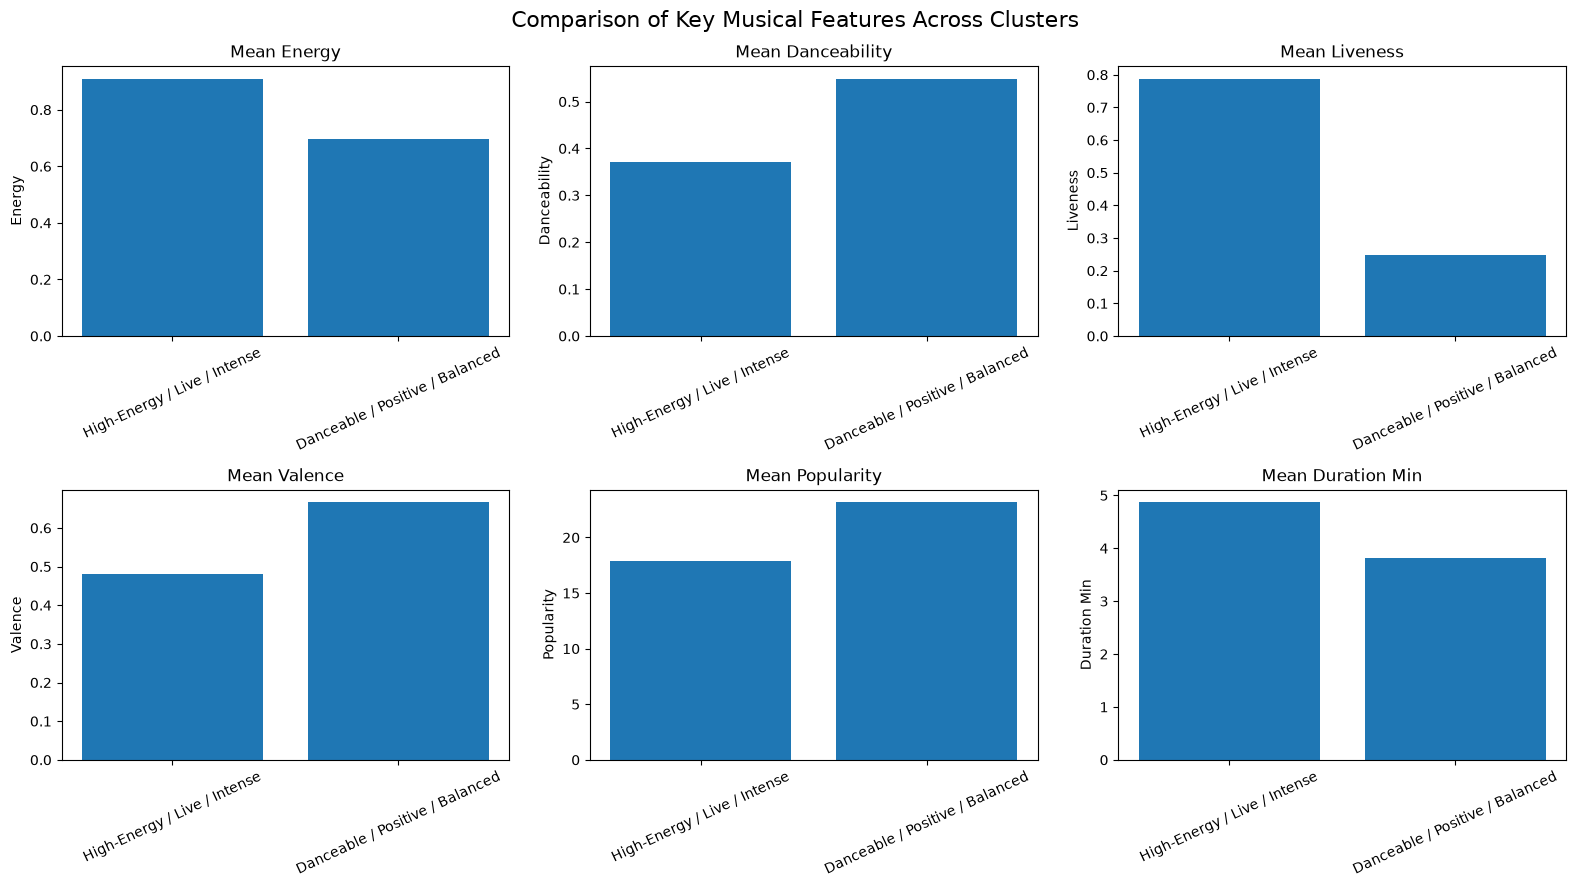

In [117]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, feature in zip(axes.flat, important_features):

    values = plot_data[feature]

    ax.bar(
        plot_data["cluster_label"],
        values
    )

    ax.set_title(f"Mean {feature.replace('_', ' ').title()}")
    ax.set_ylabel(feature.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=25)

plt.suptitle(
    "Comparison of Key Musical Features Across Clusters",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [118]:
for cluster_id in sorted(df_clustered["cluster"].unique()):

    cluster_data = df_clustered[
        df_clustered["cluster"] == cluster_id
    ]

    label = cluster_data["cluster_label"].iloc[0]

    print(f"\nCluster {cluster_id}: {label}")
    print("-" * 60)

    print(f"Tracks: {len(cluster_data)}")

    print(
        f"Average Energy: "
        f"{cluster_data['energy'].mean():.3f}"
    )

    print(
        f"Average Danceability: "
        f"{cluster_data['danceability'].mean():.3f}"
    )

    print(
        f"Average Liveness: "
        f"{cluster_data['liveness'].mean():.3f}"
    )

    print(
        f"Average Valence: "
        f"{cluster_data['valence'].mean():.3f}"
    )

    print(
        f"Average Popularity: "
        f"{cluster_data['popularity'].mean():.2f}"
    )

    print(
        f"Average Duration: "
        f"{cluster_data['duration_min'].mean():.2f} minutes"
    )


Cluster 0: High-Energy / Live / Intense
------------------------------------------------------------
Tracks: 728
Average Energy: 0.910
Average Danceability: 0.372
Average Liveness: 0.788
Average Valence: 0.480
Average Popularity: 17.92
Average Duration: 4.87 minutes

Cluster 1: Danceable / Positive / Balanced
------------------------------------------------------------
Tracks: 882
Average Energy: 0.695
Average Danceability: 0.549
Average Liveness: 0.247
Average Valence: 0.666
Average Popularity: 23.16
Average Duration: 3.82 minutes


In [119]:
feature_columns = [
    "acousticness",
    "danceability",
    "energy",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "tempo",
    "valence",
    "popularity",
    "duration_ms"
]

print("\nFeatures used:")
print(feature_columns)

print("\nFeature matrix shape:")
print(X_final.shape)


Features used:
['acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'popularity', 'duration_ms']

Feature matrix shape:
(1610, 11)


In [120]:
from sklearn.metrics import pairwise_distances

# Calculate distance of every track from every cluster centroid
distances = pairwise_distances(
    X_final,
    kmeans.cluster_centers_,
    metric="euclidean"
)

print("Distance matrix shape:")
print(distances.shape)

Distance matrix shape:
(1610, 2)


In [121]:
df_clustered["centroid_distance"] = [
    distances[i, cluster]
    for i, cluster in enumerate(df_clustered["cluster"])
]

print("Centroid distances added successfully.")

display(
    df_clustered[
        [
            "name",
            "album",
            "cluster",
            "cluster_label",
            "centroid_distance"
        ]
    ].head(10)
)

Centroid distances added successfully.


,name,album,cluster,cluster_label,centroid_distance
0,Concert Intro Music - Live,Licked Live In NYC,0,High-Energy / Live / Intense,5.1943
1,Street Fighting Man - Live,Licked Live In NYC,0,High-Energy / Live / Intense,2.0427
2,Start Me Up - Live,Licked Live In NYC,0,High-Energy / Live / Intense,2.1197
3,If You Can't Rock Me - Live,Licked Live In NYC,0,High-Energy / Live / Intense,3.1838
4,Don’t Stop - Live,Licked Live In NYC,0,High-Energy / Live / Intense,2.0763
5,Monkey Man - Live,Licked Live In NYC,0,High-Energy / Live / Intense,2.2834
6,Angie - Live,Licked Live In NYC,0,High-Energy / Live / Intense,3.0902
7,Let It Bleed - Live,Licked Live In NYC,0,High-Energy / Live / Intense,1.4928
8,Midnight Rambler - Live,Licked Live In NYC,0,High-Energy / Live / Intense,4.9231
9,Tumbling Dice - Live,Licked Live In NYC,0,High-Energy / Live / Intense,2.1456


In [122]:
representative_tracks = {}

for cluster_id in sorted(df_clustered["cluster"].unique()):

    representative_tracks[cluster_id] = (
        df_clustered[
            df_clustered["cluster"] == cluster_id
        ]
        .sort_values("centroid_distance")
        .head(10)
        [
            [
                "name",
                "album",
                "popularity",
                "energy",
                "danceability",
                "liveness",
                "valence",
                "tempo",
                "duration_ms",
                "centroid_distance"
            ]
        ]
        .reset_index(drop=True)
    )

In [123]:
print("=" * 80)
print("CLUSTER 0 — REPRESENTATIVE TRACKS")
print("High-Energy / Live / Intense")
print("=" * 80)

display(representative_tracks[0])

CLUSTER 0 — REPRESENTATIVE TRACKS
High-Energy / Live / Intense


,name,album,popularity,energy,danceability,liveness,valence,tempo,duration_ms,centroid_distance
0,Doo Doo Doo Doo Doo (Heartbreaker) - Live / Fo...,Goats Head Soup (Deluxe),20,0.9250,0.3190,0.9320,0.5320,125.3350,303213,1.0679
1,Live With Me - Live At University Of Leeds / 1971,Sticky Fingers (Super Deluxe),15,0.9570,0.4210,0.8940,0.5840,137.1700,261440,1.0965
2,Start Me Up - Live,Sticky Fingers Live At The Fonda Theatre,20,0.9450,0.3940,0.9840,0.4990,128.4910,274493,1.0974
3,Brown Sugar - Live At University Of Leeds / 1971,Sticky Fingers (Super Deluxe),18,0.9270,0.3970,0.6730,0.4270,137.8410,284013,1.1329
4,All Down The Line - Live,Havana Moon (Live),20,0.9440,0.3800,0.9850,0.5240,132.3610,322749,1.1568
5,Tumbling Dice - Live,Havana Moon (Live),22,0.9320,0.4040,0.9640,0.4410,119.1630,303274,1.1588
6,Tumbling Dice - Live,Some Girls: Live In Texas '78,19,0.9800,0.3840,0.8530,0.5550,119.3660,278893,1.1753
7,It's Only Rock 'N' Roll (But I Like It) - Live,Voodoo Lounge Uncut (Live),13,0.9330,0.4900,0.7900,0.5580,135.7370,319025,1.2120
8,Start Me Up - Live,Bridges To Buenos Aires (Live),19,0.9790,0.4200,0.9430,0.4620,123.5410,260079,1.2165
9,It's Only Rock 'n Roll - Live,From The Vault: No Security - San Jose 1999 (L...,15,0.9750,0.4780,0.6830,0.4200,137.0740,336400,1.2252


In [124]:
print("=" * 80)
print("CLUSTER 1 — REPRESENTATIVE TRACKS")
print("Danceable / Positive / Balanced")
print("=" * 80)

display(representative_tracks[1])

CLUSTER 1 — REPRESENTATIVE TRACKS
Danceable / Positive / Balanced


,name,album,popularity,energy,danceability,liveness,valence,tempo,duration_ms,centroid_distance
0,Who's Been Sleeping Here?,Between The Buttons,25,0.6140,0.5490,0.1180,0.6910,115.7400,235333,1.0366
1,Who's Been Sleeping Here?,Between The Buttons (UK Version),15,0.6130,0.5490,0.1180,0.6450,115.7350,235333,1.1859
2,Blue Turns To Grey,December’s Children (And Everybody’s),25,0.6730,0.5810,0.1650,0.7360,112.5170,148813,1.2129
3,Casino Boogie,Exile On Main Street (Deluxe Version),29,0.6910,0.5300,0.2900,0.5810,117.0460,214466,1.2345
4,Hand Of Fate,Black And Blue,21,0.7050,0.6340,0.0862,0.8250,116.1720,267933,1.3822
5,"Cool, Calm And Collected",Between The Buttons,27,0.8530,0.6200,0.1750,0.7210,107.9690,255120,1.3959
6,Ride On Baby,Flowers,26,0.6710,0.5500,0.2400,0.8530,131.2180,172600,1.4290
7,You Better Move On,December’s Children (And Everybody’s),31,0.6750,0.6160,0.2210,0.7570,115.8810,159493,1.4747
8,The Under Assistant West Coast Promotion Man -...,Out Of Our Heads,30,0.6720,0.5700,0.2690,0.6140,136.8830,187346,1.4764
9,Doo Doo Doo Doo Doo (Heartbreaker),Goats Head Soup (Deluxe),32,0.8280,0.4680,0.2270,0.6860,110.0440,206040,1.4883


In [125]:
representative_all = pd.concat(
    [
        df_clustered[
            df_clustered["cluster"] == cluster_id
        ]
        .sort_values("centroid_distance")
        .head(10)
        .assign(rank=range(1, 11))
        for cluster_id in sorted(df_clustered["cluster"].unique())
    ],
    ignore_index=True
)

representative_all = representative_all[
    [
        "cluster",
        "cluster_label",
        "rank",
        "name",
        "album",
        "popularity",
        "energy",
        "danceability",
        "liveness",
        "valence",
        "tempo",
        "duration_ms",
        "centroid_distance"
    ]
]

display(representative_all)

,cluster,cluster_label,rank,name,album,popularity,energy,danceability,liveness,valence,tempo,duration_ms,centroid_distance
0,0,High-Energy / Live / Intense,1,Doo Doo Doo Doo Doo (Heartbreaker) - Live / Fo...,Goats Head Soup (Deluxe),20,0.9250,0.3190,0.9320,0.5320,125.3350,303213,1.0679
1,0,High-Energy / Live / Intense,2,Live With Me - Live At University Of Leeds / 1971,Sticky Fingers (Super Deluxe),15,0.9570,0.4210,0.8940,0.5840,137.1700,261440,1.0965
2,0,High-Energy / Live / Intense,3,Start Me Up - Live,Sticky Fingers Live At The Fonda Theatre,20,0.9450,0.3940,0.9840,0.4990,128.4910,274493,1.0974
3,0,High-Energy / Live / Intense,4,Brown Sugar - Live At University Of Leeds / 1971,Sticky Fingers (Super Deluxe),18,0.9270,0.3970,0.6730,0.4270,137.8410,284013,1.1329
4,0,High-Energy / Live / Intense,5,All Down The Line - Live,Havana Moon (Live),20,0.9440,0.3800,0.9850,0.5240,132.3610,322749,1.1568
5,0,High-Energy / Live / Intense,6,Tumbling Dice - Live,Havana Moon (Live),22,0.9320,0.4040,0.9640,0.4410,119.1630,303274,1.1588
6,0,High-Energy / Live / Intense,7,Tumbling Dice - Live,Some Girls: Live In Texas '78,19,0.9800,0.3840,0.8530,0.5550,119.3660,278893,1.1753
7,0,High-Energy / Live / Intense,8,It's Only Rock 'N' Roll (But I Like It) - Live,Voodoo Lounge Uncut (Live),13,0.9330,0.4900,0.7900,0.5580,135.7370,319025,1.2120
8,0,High-Energy / Live / Intense,9,Start Me Up - Live,Bridges To Buenos Aires (Live),19,0.9790,0.4200,0.9430,0.4620,123.5410,260079,1.2165
9,0,High-Energy / Live / Intense,10,It's Only Rock 'n Roll - Live,From The Vault: No Security - San Jose 1999 (L...,15,0.9750,0.4780,0.6830,0.4200,137.0740,336400,1.2252


In [131]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import numpy as np


def recommend_tracks(track_name, n_recommendations=10):
    """
    Recommend tracks similar to the selected track using
    standardized audio features and cluster information.
    """

    required_columns = [
        "name",
        "cluster",
        "cluster_label"
    ] + feature_columns

    missing_columns = [
        col for col in required_columns
        if col not in df_clustered.columns
    ]

    if missing_columns:
        raise ValueError(
            f"df_clustered is missing required columns: {missing_columns}"
        )

    matches = df_clustered[
        df_clustered["name"]
        .astype(str)
        .str.strip()
        .str.lower()
        == str(track_name).strip().lower()
    ]

    if matches.empty:
        raise ValueError(
            f"Track '{track_name}' was not found in df_clustered."
        )

    # Use the first matching track
    target_position = matches.index[0]

    target_row = df_clustered.loc[target_position]

    target_cluster = target_row["cluster"]

    feature_matrix = df_clustered[feature_columns].copy()

    # Make sure all feature values are numeric
    feature_matrix = feature_matrix.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Remove rows with invalid feature values
    valid_mask = feature_matrix.notna().all(axis=1)

    feature_matrix = feature_matrix.loc[valid_mask]

    if target_position not in feature_matrix.index:
        raise ValueError(
            f"Target track '{track_name}' does not have valid feature values."
        )

    target_vector = feature_matrix.loc[[target_position]]

    similarity_scores = cosine_similarity(
        target_vector,
        feature_matrix
    )[0]

    similarity_df = pd.DataFrame({
        "index": feature_matrix.index,
        "similarity": similarity_scores
    })

    similarity_df["cluster"] = similarity_df["index"].map(
        df_clustered["cluster"]
    )

    similarity_df = similarity_df[
        similarity_df["index"] != target_position
    ]

    same_cluster = similarity_df[
        similarity_df["cluster"] == target_cluster
    ].copy()

    other_clusters = similarity_df[
        similarity_df["cluster"] != target_cluster
    ].copy()

    same_cluster = same_cluster.sort_values(
        "similarity",
        ascending=False
    )

    other_clusters = other_clusters.sort_values(
        "similarity",
        ascending=False
    )

    recommendations = pd.concat(
        [same_cluster, other_clusters]
    ).head(n_recommendations)

    result = df_clustered.loc[
        recommendations["index"],
        [
            "name",
            "album",
            "cluster",
            "cluster_label",
            "popularity",
            "energy",
            "danceability",
            "liveness",
            "valence",
            "tempo"
        ]
    ].copy()

    # Add similarity score
    result["similarity"] = recommendations["similarity"].values

    # Reset index for clean presentation
    result = result.reset_index(drop=True)

    return result

In [133]:
test_track = "Paint It, Black"

recommendations = recommend_tracks(
    test_track,
    n_recommendations=10
)

print(f"\nInput track:")
print(test_track)

print("\nRecommendations:")
display(recommendations)

print("\nNumber of recommendations:")
print(len(recommendations))

print("\nRecommended clusters:")
print(recommendations["cluster"].value_counts())

print("\nAverage similarity:")
print(round(recommendations["similarity"].mean(), 4))

print("\nPhase 4 recommendation engine validation complete.")


Input track:
Paint It, Black

Recommendations:


,name,album,cluster,cluster_label,popularity,energy,danceability,liveness,valence,tempo,similarity
0,Play With Fire - Mono Version,Out Of Our Heads,1,Danceable / Positive / Balanced,56,0.4290,0.5780,0.1710,0.0889,108.7380,1.0000
1,Get Off Of My Cloud - Mono Version,December’s Children (And Everybody’s),1,Danceable / Positive / Balanced,55,0.8770,0.5790,0.0656,0.9000,126.3360,1.0000
2,Just Your Fool,Blue & Lonesome,1,Danceable / Positive / Balanced,42,0.9030,0.5470,0.3880,0.8420,116.1520,1.0000
3,Rip This Joint,Exile On Main Street (2010 Re-Mastered),1,Danceable / Positive / Balanced,49,0.9520,0.5480,0.3010,0.9060,98.0400,1.0000
4,As Tears Go By - Mono Version,December’s Children (And Everybody’s),1,Danceable / Positive / Balanced,56,0.2770,0.3310,0.1810,0.3660,112.7800,1.0000
5,Susie Q,12 X 5,1,Danceable / Positive / Balanced,32,0.7620,0.5060,0.2110,0.9670,80.8400,1.0000
6,Parachute Woman - 50th Anniversary Edition,Beggars Banquet (50th Anniversary Edition),1,Danceable / Positive / Balanced,37,0.6300,0.5190,0.1680,0.8390,114.4160,1.0000
7,Happy,Exile On Main Street (Deluxe Version),1,Danceable / Positive / Balanced,49,0.8970,0.5550,0.5360,0.9650,131.7120,1.0000
8,You Got The Silver,Let It Bleed,1,Danceable / Positive / Balanced,42,0.3710,0.4710,0.1370,0.5430,143.8920,1.0000
9,Turd On The Run,Exile On Main Street (2010 Re-Mastered),1,Danceable / Positive / Balanced,37,0.7810,0.5170,0.3410,0.7420,119.3640,1.0000



Number of recommendations:
10

Recommended clusters:
cluster
1    10
Name: count, dtype: int64

Average similarity:
1.0

Phase 4 recommendation engine validation complete.


In [ ]:
print("X_scaled type:", type(X_scaled))
print("X_scaled shape:", X_scaled.shape)

if isinstance(X_scaled, pd.DataFrame):
    print("X_scaled columns:")
    print(X_scaled.columns.tolist())

    print("\nFirst 5 rows:")
    display(X_scaled.head())

In [135]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import numpy as np


def recommend_tracks(track_name, n_recommendations=10):

    required_columns = [
        "name",
        "cluster",
        "cluster_label"
    ]

    missing_columns = [
        col for col in required_columns
        if col not in df_clustered.columns
    ]

    if missing_columns:
        raise ValueError(
            f"df_clustered is missing required columns: {missing_columns}"
        )

    if not isinstance(X_scaled, pd.DataFrame):
        raise TypeError(
            "X_scaled must be a pandas DataFrame."
        )

    missing_features = [
        col for col in feature_columns
        if col not in X_scaled.columns
    ]

    if missing_features:
        raise ValueError(
            f"X_scaled is missing features: {missing_features}"
        )

    common_indices = df_clustered.index.intersection(
        X_scaled.index
    )

    if len(common_indices) != len(df_clustered):
        raise ValueError(
            "X_scaled and df_clustered do not have matching indices."
        )

    scaled_features = X_scaled.loc[
        df_clustered.index,
        feature_columns
    ].copy()

    matches = df_clustered[
        df_clustered["name"]
        .astype(str)
        .str.strip()
        .str.lower()
        ==
        str(track_name).strip().lower()
    ]

    if matches.empty:
        raise ValueError(
            f"Track '{track_name}' was not found."
        )

    target_index = matches.index[0]

    target_cluster = df_clustered.loc[
        target_index,
        "cluster"
    ]

    target_vector = scaled_features.loc[
        [target_index]
    ].values

    all_vectors = scaled_features.values

    similarity_scores = cosine_similarity(
        target_vector,
        all_vectors
    )[0]

    similarity_df = pd.DataFrame({
        "index": df_clustered.index,
        "similarity": similarity_scores
    })

    # Add cluster
    similarity_df["cluster"] = similarity_df["index"].map(
        df_clustered["cluster"]
    )

    similarity_df = similarity_df[
        similarity_df["index"] != target_index
    ].copy()

    same_cluster = similarity_df[
        similarity_df["cluster"] == target_cluster
    ].copy()

    other_clusters = similarity_df[
        similarity_df["cluster"] != target_cluster
    ].copy()

    same_cluster = same_cluster.sort_values(
        by="similarity",
        ascending=False
    )

    other_clusters = other_clusters.sort_values(
        by="similarity",
        ascending=False
    )

    recommendations = pd.concat(
        [
            same_cluster,
            other_clusters
        ]
    ).head(n_recommendations)

    result = df_clustered.loc[
        recommendations["index"],
        [
            "name",
            "album",
            "cluster",
            "cluster_label",
            "popularity",
            "energy",
            "danceability",
            "liveness",
            "valence",
            "tempo"
        ]
    ].copy()

    result["similarity"] = (
        recommendations["similarity"].values
    )

    result = result.reset_index(drop=True)

    return result

recommendations = recommend_tracks(
    "Paint It, Black",
    n_recommendations=10
)

display(recommendations)

,name,album,cluster,cluster_label,popularity,energy,danceability,liveness,valence,tempo,similarity
0,Street Fighting Man - 50th Anniversary Edition,Beggars Banquet (50th Anniversary Edition),1,Danceable / Positive / Balanced,56,0.8550,0.5830,0.2620,0.6900,128.1780,0.8675
1,(I Can't Get No) Satisfaction - Mono Version,Out Of Our Heads,1,Danceable / Positive / Balanced,76,0.8630,0.7230,0.1280,0.9310,136.3020,0.8498
2,Gimme Shelter,Let It Bleed,1,Danceable / Positive / Balanced,76,0.6300,0.6340,0.1700,0.4890,118.6280,0.8043
3,Start Me Up - Remastered 2009,Tattoo You (2009 Re-Mastered),1,Danceable / Positive / Balanced,76,0.9320,0.6310,0.0918,0.9710,122.4290,0.7945
4,Waiting On A Friend - Remastered 2009,Tattoo You (2009 Re-Mastered),1,Danceable / Positive / Balanced,59,0.7940,0.6060,0.5680,0.9110,116.9300,0.7574
5,Anybody Seen My Baby? - Remastered,Bridges To Babylon (Remastered),1,Danceable / Positive / Balanced,61,0.7420,0.6050,0.2560,0.4700,105.0400,0.7419
6,Don't Stop,Honk (Deluxe),1,Danceable / Positive / Balanced,44,0.8570,0.4740,0.1930,0.7270,127.0030,0.7335
7,Brown Sugar - 2009 Remaster,Sticky Fingers (Remastered),1,Danceable / Positive / Balanced,66,0.9340,0.6330,0.0592,0.9630,128.6060,0.7301
8,Love Is Strong,Voodoo Lounge (Remastered 2009),1,Danceable / Positive / Balanced,53,0.8550,0.5300,0.0628,0.5110,110.1400,0.7298
9,Tell Me,The Rolling Stones,1,Danceable / Positive / Balanced,36,0.7060,0.5090,0.5160,0.4460,122.0150,0.7287


In [136]:
test_tracks = [
    "Paint It, Black",
    "Gimme Shelter",
    "Start Me Up - Live",
    "Happy",
    "Satisfaction - Live"
]

for track in test_tracks:

    print("=" * 70)
    print(f"INPUT TRACK: {track}")
    print("=" * 70)

    try:

        # Find input track
        matches = df_clustered[
            df_clustered["name"]
            .astype(str)
            .str.strip()
            .str.lower()
            ==
            track.strip().lower()
        ]

        if matches.empty:
            print("Track not found.")
            continue

        input_index = matches.index[0]

        input_cluster = df_clustered.loc[
            input_index,
            "cluster"
        ]

        input_label = df_clustered.loc[
            input_index,
            "cluster_label"
        ]

        print(f"Input cluster: {input_cluster}")
        print(f"Input label: {input_label}")

        # Generate recommendations
        recommendations = recommend_tracks(
            track,
            n_recommendations=10
        )

        display(
            recommendations[
                [
                    "name",
                    "album",
                    "cluster_label",
                    "popularity",
                    "energy",
                    "danceability",
                    "valence",
                    "similarity"
                ]
            ]
        )

    except Exception as e:

        print(f"Error while processing '{track}':")
        print(e)

INPUT TRACK: Paint It, Black
Input cluster: 1
Input label: Danceable / Positive / Balanced


,name,album,cluster_label,popularity,energy,danceability,valence,similarity
0,Street Fighting Man - 50th Anniversary Edition,Beggars Banquet (50th Anniversary Edition),Danceable / Positive / Balanced,56,0.8550,0.5830,0.6900,0.8675
1,(I Can't Get No) Satisfaction - Mono Version,Out Of Our Heads,Danceable / Positive / Balanced,76,0.8630,0.7230,0.9310,0.8498
2,Gimme Shelter,Let It Bleed,Danceable / Positive / Balanced,76,0.6300,0.6340,0.4890,0.8043
3,Start Me Up - Remastered 2009,Tattoo You (2009 Re-Mastered),Danceable / Positive / Balanced,76,0.9320,0.6310,0.9710,0.7945
4,Waiting On A Friend - Remastered 2009,Tattoo You (2009 Re-Mastered),Danceable / Positive / Balanced,59,0.7940,0.6060,0.9110,0.7574
5,Anybody Seen My Baby? - Remastered,Bridges To Babylon (Remastered),Danceable / Positive / Balanced,61,0.7420,0.6050,0.4700,0.7419
6,Don't Stop,Honk (Deluxe),Danceable / Positive / Balanced,44,0.8570,0.4740,0.7270,0.7335
7,Brown Sugar - 2009 Remaster,Sticky Fingers (Remastered),Danceable / Positive / Balanced,66,0.9340,0.6330,0.9630,0.7301
8,Love Is Strong,Voodoo Lounge (Remastered 2009),Danceable / Positive / Balanced,53,0.8550,0.5300,0.5110,0.7298
9,Tell Me,The Rolling Stones,Danceable / Positive / Balanced,36,0.7060,0.5090,0.4460,0.7287


INPUT TRACK: Gimme Shelter
Input cluster: 1
Input label: Danceable / Positive / Balanced


,name,album,cluster_label,popularity,energy,danceability,valence,similarity
0,Gimme Shelter - Remastered 2019,Let It Bleed (50th Anniversary Edition / Remas...,Danceable / Positive / Balanced,49,0.6200,0.6460,0.5150,0.9167
1,Slipping Away - Live / Remastered 2009,Stripped,Danceable / Positive / Balanced,26,0.4890,0.6020,0.5330,0.8879
2,Under The Boardwalk,12 X 5,Danceable / Positive / Balanced,35,0.4920,0.7030,0.5930,0.8818
3,No Use In Crying - Remastered,Tattoo You (2009 Re-Mastered),Danceable / Positive / Balanced,38,0.4550,0.6360,0.4320,0.8673
4,Melody - Remastered,Black And Blue (Remastered 2009),Danceable / Positive / Balanced,36,0.5170,0.6570,0.5740,0.8516
5,Almost Hear You Sigh,Steel Wheels,Danceable / Positive / Balanced,26,0.5600,0.7250,0.7620,0.8478
6,Wild Horses - Live / Remastered 2009,Stripped,Danceable / Positive / Balanced,35,0.4700,0.5660,0.2030,0.8464
7,Prodigal Son - 50th Anniversary Edition,Beggars Banquet (50th Anniversary Edition),Danceable / Positive / Balanced,37,0.5970,0.6270,0.0938,0.8286
8,Under The Boardwalk,The Rolling Stones No. 2,Danceable / Positive / Balanced,25,0.4550,0.7050,0.6010,0.8269
9,All About You - Remastered,Emotional Rescue (2009 Re-Mastered),Danceable / Positive / Balanced,29,0.3840,0.6200,0.2240,0.8205


INPUT TRACK: Start Me Up - Live
Input cluster: 0
Input label: High-Energy / Live / Intense


,name,album,cluster_label,popularity,energy,danceability,valence,similarity
0,Street Fighting Man - Live,Licked Live In NYC,High-Energy / Live / Intense,34,0.9650,0.3260,0.3180,0.9274
1,Brown Sugar - Live,Licked Live In NYC,High-Energy / Live / Intense,25,0.9890,0.3400,0.1640,0.8958
2,Tumbling Dice - Live,A Bigger Bang (Live),High-Energy / Live / Intense,18,0.9710,0.3300,0.2630,0.8861
3,When The Whip Comes Down - Live,Licked Live In NYC,High-Energy / Live / Intense,24,0.9860,0.2920,0.1790,0.8749
4,Satisfaction - Live,Licked Live In NYC,High-Energy / Live / Intense,28,0.9790,0.2560,0.2400,0.8678
5,Don’t Stop - Live,Licked Live In NYC,High-Energy / Live / Intense,32,0.9690,0.3030,0.2060,0.8568
6,It's Only Rock 'N' Roll (But I Like It) - Live,A Bigger Bang (Live),High-Energy / Live / Intense,19,0.9950,0.3530,0.1310,0.8535
7,Tumbling Dice - Live,Licked Live In NYC,High-Energy / Live / Intense,29,0.9440,0.3100,0.1880,0.8519
8,You Got Me Rocking - Live,Licked Live In NYC,High-Energy / Live / Intense,26,0.9740,0.3880,0.1660,0.8445
9,It's Only Rock 'N' Roll - Live,Licked Live In NYC,High-Energy / Live / Intense,25,0.9860,0.3780,0.4360,0.8314


INPUT TRACK: Happy
Input cluster: 1
Input label: Danceable / Positive / Balanced


,name,album,cluster_label,popularity,energy,danceability,valence,similarity
0,Happy,Exile On Main Street (2010 Re-Mastered),Danceable / Positive / Balanced,41,0.8970,0.5550,0.9650,0.9845
1,Commit A Crime,Blue & Lonesome,Danceable / Positive / Balanced,33,0.8020,0.5630,0.7770,0.9539
2,Happy,Exile On Main Street (Deluxe Version),Danceable / Positive / Balanced,49,0.8970,0.5550,0.9650,0.9529
3,When The Whip Comes Down - Remastered,Some Girls,Danceable / Positive / Balanced,40,0.9860,0.4990,0.8350,0.9111
4,Rip This Joint,Exile On Main Street (Deluxe Version),Danceable / Positive / Balanced,32,0.9520,0.5480,0.9060,0.8906
5,When The Whip Comes Down - Remastered,Some Girls (Deluxe Version),Danceable / Positive / Balanced,20,0.9860,0.4990,0.8350,0.8842
6,All The Way Down - Remastered,Undercover (2009 Re-Mastered),Danceable / Positive / Balanced,21,0.9490,0.5720,0.8060,0.8841
7,Little Queenie - Live,Get Yer Ya-Ya's Out! The Rolling Stones In Con...,Danceable / Positive / Balanced,27,0.8120,0.5060,0.9640,0.8813
8,Stop Breaking Down,Exile On Main Street (2010 Re-Mastered),Danceable / Positive / Balanced,38,0.8910,0.5220,0.9100,0.8743
9,When The Whip Comes Down - Remastered,Some Girls (Deluxe Version),Danceable / Positive / Balanced,18,0.9860,0.4990,0.8350,0.8723


INPUT TRACK: Satisfaction - Live
Input cluster: 0
Input label: High-Energy / Live / Intense


,name,album,cluster_label,popularity,energy,danceability,valence,similarity
0,Jumpin Jack Flash - Live,Licked Live In NYC,High-Energy / Live / Intense,25,0.9640,0.1920,0.1910,0.9219
1,Don’t Stop - Live,Licked Live In NYC,High-Energy / Live / Intense,32,0.9690,0.3030,0.2060,0.9161
2,Street Fighting Man - Live,Licked Live In NYC,High-Energy / Live / Intense,34,0.9650,0.3260,0.3180,0.9058
3,When The Whip Comes Down - Live,Licked Live In NYC,High-Energy / Live / Intense,24,0.9860,0.2920,0.1790,0.9010
4,Tumbling Dice - Live,Licked Live In NYC,High-Energy / Live / Intense,29,0.9440,0.3100,0.1880,0.8887
5,Brown Sugar - Live,Licked Live In NYC,High-Energy / Live / Intense,25,0.9890,0.3400,0.1640,0.8844
6,Tumbling Dice - Live,A Bigger Bang (Live),High-Energy / Live / Intense,18,0.9710,0.3300,0.2630,0.8701
7,Gimme Shelter - Live,Licked Live In NYC,High-Energy / Live / Intense,28,0.9800,0.3600,0.1360,0.8683
8,Start Me Up - Live,Licked Live In NYC,High-Energy / Live / Intense,34,0.9690,0.3860,0.3130,0.8678
9,Night Time Is The Right Time - Live,A Bigger Bang (Live),High-Energy / Live / Intense,18,0.9650,0.2980,0.2370,0.8533


In [137]:
evaluation_results = []

for track in test_tracks:

    matches = df_clustered[
        df_clustered["name"]
        .astype(str)
        .str.strip()
        .str.lower()
        ==
        track.strip().lower()
    ]

    if matches.empty:
        continue

    input_index = matches.index[0]

    input_cluster = df_clustered.loc[
        input_index,
        "cluster"
    ]

    input_label = df_clustered.loc[
        input_index,
        "cluster_label"
    ]

    recommendations = recommend_tracks(
        track,
        n_recommendations=10
    )

    same_cluster_count = (
        recommendations["cluster"]
        == input_cluster
    ).sum()

    same_cluster_percentage = (
        same_cluster_count
        / len(recommendations)
        * 100
    )

    evaluation_results.append({
        "input_track": track,
        "input_cluster": input_cluster,
        "cluster_label": input_label,
        "recommendation_count": len(recommendations),
        "same_cluster_count": same_cluster_count,
        "same_cluster_percentage": round(
            same_cluster_percentage,
            2
        ),
        "mean_similarity": round(
            recommendations["similarity"].mean(),
            4
        ),
        "min_similarity": round(
            recommendations["similarity"].min(),
            4
        ),
        "max_similarity": round(
            recommendations["similarity"].max(),
            4
        )
    })


evaluation_summary = pd.DataFrame(
    evaluation_results
)

display(evaluation_summary)

,input_track,input_cluster,cluster_label,recommendation_count,same_cluster_count,same_cluster_percentage,mean_similarity,min_similarity,max_similarity
0,"Paint It, Black",1,Danceable / Positive / Balanced,10,10,100.0000,0.7737,0.7287,0.8675
1,Gimme Shelter,1,Danceable / Positive / Balanced,10,10,100.0000,0.8575,0.8205,0.9167
2,Start Me Up - Live,0,High-Energy / Live / Intense,10,10,100.0000,0.8690,0.8314,0.9274
3,Happy,1,Danceable / Positive / Balanced,10,10,100.0000,0.9089,0.8723,0.9845
4,Satisfaction - Live,0,High-Energy / Live / Intense,10,10,100.0000,0.8877,0.8533,0.9219


In [138]:
print("\nTracks evaluated:")
print(len(evaluation_summary))

print("\nTotal recommendations evaluated:")
print(
    evaluation_summary["recommendation_count"].sum()
)

print("\nAverage same-cluster percentage:")
print(
    round(
        evaluation_summary[
            "same_cluster_percentage"
        ].mean(),
        2
    ),
    "%"
)

print("\nAverage similarity:")
print(
    round(
        evaluation_summary[
            "mean_similarity"
        ].mean(),
        4
    )
)

print("\nMinimum observed similarity:")
print(
    round(
        evaluation_summary[
            "min_similarity"
        ].min(),
        4
    )
)

print("\nMaximum observed similarity:")
print(
    round(
        evaluation_summary[
            "max_similarity"
        ].max(),
        4
    )
)


Tracks evaluated:
5

Total recommendations evaluated:
50

Average same-cluster percentage:
100.0 %

Average similarity:
0.8594

Minimum observed similarity:
0.7287

Maximum observed similarity:
0.9845


In [141]:
print("\nDataset Information")
print("-" * 40)

print(f"Number of tracks: {len(df_clustered)}")
print(f"Number of features used for clustering: {X_final.shape[1]}")
print(f"Number of clusters: {len(set(cluster_labels))}")

print("\nCluster Assignment Validation")
print("-" * 40)

print(f"Total cluster labels: {len(cluster_labels)}")
print(f"Dataset rows: {len(df_clustered)}")

if len(cluster_labels) == len(df_clustered):
    print("Every track has a cluster assignment.")
else:
    print("Cluster assignment count does not match dataset size.")

missing_clusters = df_clustered["cluster"].isna().sum()

print(f"\nMissing cluster assignments: {missing_clusters}")

if missing_clusters == 0:
    print("No missing cluster assignments.")
else:
    print("Missing cluster assignments detected.")
cluster_distribution = (
    df_clustered["cluster"]
    .value_counts()
    .sort_index()
)

print("\nCluster Distribution")
print("-" * 40)
print(cluster_distribution)

if "id" in df_clustered.columns:
    duplicate_ids = df_clustered["id"].duplicated().sum()

    print(f"\nDuplicate track IDs: {duplicate_ids}")

    if duplicate_ids == 0:
        print("No duplicate track IDs.")
    else:
        print("Duplicate track IDs detected.")


Dataset Information
----------------------------------------
Number of tracks: 1610
Number of features used for clustering: 11
Number of clusters: 2

Cluster Assignment Validation
----------------------------------------
Total cluster labels: 2
Dataset rows: 1610
Cluster assignment count does not match dataset size.

Missing cluster assignments: 0
No missing cluster assignments.

Cluster Distribution
----------------------------------------
cluster
0    728
1    882
Name: count, dtype: int64

Duplicate track IDs: 0
No duplicate track IDs.


In [144]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

K_VALUES = range(2, 11)

evaluation_rows = []

for k in K_VALUES:

    print(f"Evaluating K = {k}...")

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_final)

    inertia = model.inertia_

    silhouette = silhouette_score(
        X_final,
        labels
    )

    calinski = calinski_harabasz_score(
        X_final,
        labels
    )

    davies = davies_bouldin_score(
        X_final,
        labels
    )

    evaluation_rows.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette Score": silhouette,
        "Calinski-Harabasz Score": calinski,
        "Davies-Bouldin Score": davies
    })

evaluation_results = pd.DataFrame(
    evaluation_rows
).round(4)

print("\nComplete Clustering Evaluation")
print("-" * 70)

display(evaluation_results)

best_silhouette = evaluation_results.loc[
    evaluation_results["Silhouette Score"].idxmax()
]

best_calinski = evaluation_results.loc[
    evaluation_results["Calinski-Harabasz Score"].idxmax()
]

best_davies = evaluation_results.loc[
    evaluation_results["Davies-Bouldin Score"].idxmin()
]

print("\nBest Silhouette Score")
print("-" * 40)
print(
    f"K = {int(best_silhouette['K'])}" #type: ignore
    f" | Score = {best_silhouette['Silhouette Score']:.4f}"
)

print("\nBest Calinski-Harabasz Score")
print("-" * 40)
print(
    f"K = {int(best_calinski['K'])}" #type: ignore
    f" | Score = {best_calinski['Calinski-Harabasz Score']:.4f}"
)

print("\nBest Davies-Bouldin Score")
print("-" * 40)
print(
    f"K = {int(best_davies['K'])}" #type: ignore
    f" | Score = {best_davies['Davies-Bouldin Score']:.4f}"
)

FINAL_K = 2

selected_metrics = evaluation_results[
    evaluation_results["K"] == FINAL_K
].iloc[0]

print("\n" + "=" * 70)
print(f"FINAL SELECTED NUMBER OF CLUSTERS: K = {FINAL_K}")
print("=" * 70)

print("\nMetrics for Final K")
print("-" * 40)

print(
    f"Inertia: "
    f"{selected_metrics['Inertia']:.4f}"
)

print(
    f"Silhouette Score: "
    f"{selected_metrics['Silhouette Score']:.4f}"
)

print(
    f"Calinski-Harabasz Score: "
    f"{selected_metrics['Calinski-Harabasz Score']:.4f}"
)

print(
    f"Davies-Bouldin Score: "
    f"{selected_metrics['Davies-Bouldin Score']:.4f}"
)

Evaluating K = 2...
Evaluating K = 3...
Evaluating K = 4...
Evaluating K = 5...
Evaluating K = 6...
Evaluating K = 7...
Evaluating K = 8...
Evaluating K = 9...
Evaluating K = 10...

Complete Clustering Evaluation
----------------------------------------------------------------------


,K,Inertia,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,2,14209.9816,0.1868,396.0617,1.8999
1,3,12687.4662,0.1580,318.0782,2.0023
2,4,11776.0029,0.1454,269.7576,1.9596
3,5,11115.3215,0.1288,238.0601,2.0741
4,6,10417.8600,0.1390,224.5489,1.8858
5,7,9885.4533,0.1375,211.4681,1.7838
6,8,9392.6760,0.1459,202.6557,1.6574
7,9,9074.9577,0.1400,190.4238,1.6879
8,10,8727.6179,0.1415,182.9672,1.6212



Best Silhouette Score
----------------------------------------
K = 2 | Score = 0.1868

Best Calinski-Harabasz Score
----------------------------------------
K = 2 | Score = 396.0617

Best Davies-Bouldin Score
----------------------------------------
K = 10 | Score = 1.6212

FINAL SELECTED NUMBER OF CLUSTERS: K = 2

Metrics for Final K
----------------------------------------
Inertia: 14209.9816
Silhouette Score: 0.1868
Calinski-Harabasz Score: 396.0617
Davies-Bouldin Score: 1.8999


In [ ]:
required_columns = [
    "name",
    "album",
    "id",
    "cluster",
    "cluster_label"
]

missing_columns = [
    col for col in required_columns
    if col not in df_clustered.columns
]

print("\nRequired Column Check")
print("-" * 40)

if not missing_columns:
    print("✓ All required columns are present.")
else:
    print(f"✗ Missing columns: {missing_columns}")

print("\nDataset Size")
print("-" * 40)

print(f"Dataset rows: {len(df_clustered)}")
print(f"Cluster labels: {len(cluster_labels)}")

if len(df_clustered) == len(cluster_labels):
    print("✓ Row count matches cluster assignments.")
else:
    print("✗ Row count mismatch.")

unique_clusters = sorted(
    df_clustered["cluster"].dropna().unique()
)

print("\nCluster Values")
print("-" * 40)

print(unique_clusters)

if unique_clusters == [0, 1]:
    print("✓ Expected clusters 0 and 1 are present.")
else:
    print("✗ Unexpected cluster values detected.")

cluster_missing = df_clustered["cluster"].isna().sum()

label_missing = df_clustered["cluster_label"].isna().sum()

print("\nMissing Cluster Information")
print("-" * 40)

print(f"Missing cluster values: {cluster_missing}")
print(f"Missing cluster labels: {label_missing}")

if cluster_missing == 0:
    print("✓ No missing cluster assignments.")
else:
    print("✗ Missing cluster assignments detected.")

if label_missing == 0:
    print("✓ No missing cluster labels.")
else:
    print("✗ Missing cluster labels detected.")

label_consistency = (
    df_clustered
    .groupby("cluster")["cluster_label"]
    .nunique()
)

print("\nCluster Label Consistency")
print("-" * 40)

print(label_consistency)

if (label_consistency == 1).all():
    print("✓ Each cluster has exactly one consistent label.")
else:
    print("✗ Inconsistent cluster labels detected.")

cluster_distribution = (
    df_clustered["cluster"]
    .value_counts()
    .sort_index()
)

print("\nFinal Cluster Distribution")
print("-" * 40)

print(cluster_distribution)

if "id" in df_clustered.columns:

    duplicate_ids = df_clustered["id"].duplicated().sum()

    print("\nDuplicate Track ID Check")
    print("-" * 40)

    print(f"Duplicate IDs: {duplicate_ids}")

    if duplicate_ids == 0:
        print("✓ No duplicate track IDs.")
    else:
        print("✗ Duplicate track IDs detected.")

integrity_passed = (
    not missing_columns
    and len(df_clustered) == len(cluster_labels)
    and unique_clusters == [0, 1]
    and cluster_missing == 0
    and label_missing == 0
    and (label_consistency == 1).all()
)


Required Column Check
----------------------------------------
✓ All required columns are present.

Dataset Size
----------------------------------------
Dataset rows: 1610
Cluster labels: 2
✗ Row count mismatch.

Cluster Values
----------------------------------------
[np.int32(0), np.int32(1)]
✓ Expected clusters 0 and 1 are present.

Missing Cluster Information
----------------------------------------
Missing cluster values: 0
Missing cluster labels: 0
✓ No missing cluster assignments.
✓ No missing cluster labels.

Cluster Label Consistency
----------------------------------------
cluster
0    1
1    1
Name: cluster_label, dtype: int64
✓ Each cluster has exactly one consistent label.

Final Cluster Distribution
----------------------------------------
cluster
0    728
1    882
Name: count, dtype: int64

Duplicate Track ID Check
----------------------------------------
Duplicate IDs: 0
✓ No duplicate track IDs.


In [146]:
cluster_counts = df_clustered["cluster"].value_counts().sort_index()

print("\nCluster Distribution:")
print("-" * 40)
print(cluster_counts)

print("\nCluster Percentages:")
print("-" * 40)

cluster_percentages = (
    df_clustered["cluster"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print(cluster_percentages.round(2))

print("\nCluster Assignment Validation:")
print("-" * 40)

missing_clusters = df_clustered["cluster"].isna().sum()
unique_clusters = df_clustered["cluster"].nunique()

print(f"Missing cluster assignments: {missing_clusters}")
print(f"Unique clusters found: {unique_clusters}")

print("\nCluster Labels:")
print("-" * 40)

if "cluster_label" in df_clustered.columns:
    print(
        df_clustered[["cluster", "cluster_label"]]
        .drop_duplicates()
        .sort_values("cluster")
        .to_string(index=False)
    )
else:
    print("cluster_label column not found.")

print("\nPrediction Consistency Check:")
print("-" * 40)

predicted_clusters = kmeans.predict(X_final)

stored_clusters = df_clustered["cluster"].to_numpy()

prediction_matches = (predicted_clusters == stored_clusters).sum()
prediction_accuracy = prediction_matches / len(stored_clusters) * 100

print(f"Matching assignments: {prediction_matches}/{len(stored_clusters)}")
print(f"Assignment consistency: {prediction_accuracy:.2f}%")


Cluster Distribution:
----------------------------------------
cluster
0    728
1    882
Name: count, dtype: int64

Cluster Percentages:
----------------------------------------
cluster
0   45.2200
1   54.7800
Name: proportion, dtype: float64

Cluster Assignment Validation:
----------------------------------------
Missing cluster assignments: 0
Unique clusters found: 2

Cluster Labels:
----------------------------------------
 cluster                   cluster_label
       0    High-Energy / Live / Intense
       1 Danceable / Positive / Balanced

Prediction Consistency Check:
----------------------------------------
Matching assignments: 1610/1610
Assignment consistency: 100.00%


In [ ]:
test_tracks = []

for cluster_id in sorted(df_clustered["cluster"].unique()):

    cluster_tracks = df_clustered[
        df_clustered["cluster"] == cluster_id
    ]

    # Select the most popular track in this cluster
    test_track = (
        cluster_tracks
        .sort_values("popularity", ascending=False)
        .iloc[0]["name"]
    )

    test_tracks.append(test_track)

validation_results = []

for track_name in test_tracks:

    print("\n" + "=" * 70)
    print(f"TEST TRACK: {track_name}")
    print("=" * 70)

    try:

        recommendations = recommend_tracks(
            track_name,
            n_recommendations=10
        )

        if recommendations is None or len(recommendations) == 0:
            print("⚠ No recommendations returned.")
            continue

        recommendation_count = len(recommendations)

        print(f"\nNumber of recommendations: {recommendation_count}")

        source_cluster = (
            df_clustered[
                df_clustered["name"] == track_name
            ]["cluster"]
            .iloc[0]
        )

        recommended_clusters = recommendations["cluster"]

        same_cluster_count = (
            recommended_clusters == source_cluster
        ).sum()

        same_cluster_percentage = (
            same_cluster_count /
            recommendation_count *
            100
        )

        print(f"Source cluster: {source_cluster}")
        print(
            f"Recommendations from same cluster: "
            f"{same_cluster_count}/{recommendation_count}"
        )
        print(
            f"Same-cluster percentage: "
            f"{same_cluster_percentage:.2f}%"
        )

        if "similarity" in recommendations.columns:

            avg_similarity = recommendations["similarity"].mean()

            min_similarity = recommendations["similarity"].min()
            max_similarity = recommendations["similarity"].max()

            print(f"Average similarity: {avg_similarity:.4f}")
            print(f"Minimum similarity: {min_similarity:.4f}")
            print(f"Maximum similarity: {max_similarity:.4f}")

        else:
            avg_similarity = None

        validation_results.append({
            "track": track_name,
            "source_cluster": source_cluster,
            "recommendation_count": recommendation_count,
            "same_cluster_percentage": same_cluster_percentage,
            "average_similarity": avg_similarity
        })

    except Exception as e:

        print(f"⚠ Recommendation test failed: {e}")

print("\n" + "=" * 70)
print("RECOMMENDATION VALIDATION SUMMARY")
print("=" * 70)

if validation_results:

    recommendation_validation = pd.DataFrame(
        validation_results
    )

    display(recommendation_validation)

    print("\nAverage same-cluster percentage:")

    print(
        f"{recommendation_validation['same_cluster_percentage'].mean():.2f}%"
    )

    if (
        recommendation_validation["average_similarity"]
        .notna()
        .any()
    ):

        print("\nAverage recommendation similarity:")

        print(
            f"{recommendation_validation['average_similarity'].mean():.4f}"
        )

else:

    print("⚠ No successful recommendation tests.")


TEST TRACK: The Last Time - Mono Version

Number of recommendations: 10
Source cluster: 0
Recommendations from same cluster: 10/10
Same-cluster percentage: 100.00%
Average similarity: 0.7966
Minimum similarity: 0.7503
Maximum similarity: 0.9148

TEST TRACK: Paint It, Black

Number of recommendations: 10
Source cluster: 1
Recommendations from same cluster: 10/10
Same-cluster percentage: 100.00%
Average similarity: 0.7737
Minimum similarity: 0.7287
Maximum similarity: 0.8675

RECOMMENDATION VALIDATION SUMMARY


,track,source_cluster,recommendation_count,same_cluster_percentage,average_similarity
0,The Last Time - Mono Version,0,10,100.0000,0.7966
1,"Paint It, Black",1,10,100.0000,0.7737



Average same-cluster percentage:
100.00%

Average recommendation similarity:
0.7851


In [ ]:
test_cases = []

for cluster_id in sorted(df_clustered["cluster"].unique()):

    cluster_data = df_clustered[
        df_clustered["cluster"] == cluster_id
    ]
    test_track = (
        cluster_data
        .sort_values("popularity", ascending=False)
        .iloc[0]["name"]
    )

    test_cases.append(test_track)

final_test_results = []

for track_name in test_cases:

    print("\n" + "=" * 75)
    print(f"INPUT TRACK: {track_name}")
    print("=" * 75)

    try:

        source_rows = df_clustered[
            df_clustered["name"] == track_name
        ]

        if source_rows.empty:
            print("Source track not found.")
            continue

        source = source_rows.iloc[0]

        source_cluster = source["cluster"]

        source_label = source.get(
            "cluster_label",
            f"Cluster {source_cluster}"
        )

        print(f"\nSource Cluster : {source_cluster}")
        print(f"Cluster Label  : {source_label}")

        recommendations = recommend_tracks(
            track_name,
            n_recommendations=10
        )

        if recommendations is None or recommendations.empty:

            print("No recommendations generated.")
            continue

        recommendation_count = len(recommendations)

        print(
            f"\nRecommendations generated: "
            f"{recommendation_count}"
        )

        if "similarity" in recommendations.columns:

            similarity_values = (
                recommendations["similarity"]
                .astype(float)
            )

            print(
                f"Average similarity: "
                f"{similarity_values.mean():.4f}"
            )

            print(
                f"Minimum similarity: "
                f"{similarity_values.min():.4f}"
            )

            print(
                f"Maximum similarity: "
                f"{similarity_values.max():.4f}"
            )

            # Check ranking order
            ranking_valid = similarity_values.is_monotonic_decreasing

        else:

            ranking_valid = None

        same_cluster_count = (
            recommendations["cluster"] == source_cluster
        ).sum()

        same_cluster_percentage = (
            same_cluster_count /
            recommendation_count *
            100
        )

        print(
            f"Same-cluster recommendations: "
            f"{same_cluster_count}/{recommendation_count}"
        )

        print(
            f"Same-cluster percentage: "
            f"{same_cluster_percentage:.2f}%"
        )

        display_columns = [
            col
            for col in [
                "name",
                "album",
                "cluster",
                "cluster_label",
                "similarity"
            ]
            if col in recommendations.columns
        ]

        print("\nTop Recommendations:")

        display(
            recommendations[display_columns]
            .reset_index(drop=True)
        )

        final_test_results.append({
            "input_track": track_name,
            "source_cluster": source_cluster,
            "recommendations": recommendation_count,
            "same_cluster_percentage":
                same_cluster_percentage,
            "ranking_valid":
                ranking_valid
        })

    except Exception as e:

        print(
            f"End-to-end test failed: {e}"
        )


print("\n" + "=" * 75)
print("FINAL END-TO-END TEST SUMMARY")
print("=" * 75)

if final_test_results:

    final_test_summary = pd.DataFrame(
        final_test_results
    )

    display(final_test_summary)

    successful_tests = len(final_test_results)

    total_expected = len(test_cases)

    print(
        f"\nSuccessful test cases: "
        f"{successful_tests}/{total_expected}"
    )

    if "ranking_valid" in final_test_summary.columns:

        valid_rankings = (
            final_test_summary["ranking_valid"]
            .fillna(False)
            .sum()
        )

        print(
            f"Valid similarity rankings: "
            f"{valid_rankings}/{successful_tests}"
        )


INPUT TRACK: The Last Time - Mono Version

Source Cluster : 0
Cluster Label  : High-Energy / Live / Intense

Recommendations generated: 10
Average similarity: 0.7966
Minimum similarity: 0.7503
Maximum similarity: 0.9148
Same-cluster recommendations: 10/10
Same-cluster percentage: 100.00%

Top Recommendations:


,name,album,cluster,cluster_label,similarity
0,Sway - 2009 Mix,Sticky Fingers (Remastered),0,High-Energy / Live / Intense,0.9148
1,Paint It Black - Live / Remastered 2009,Flashpoint,0,High-Energy / Live / Intense,0.8520
2,Sad Sad Sad - Remastered,Steel Wheels (Remastered 2009),0,High-Energy / Live / Intense,0.8430
3,Sway - 2009 Mix,Sticky Fingers (Deluxe),0,High-Energy / Live / Intense,0.7911
4,Down In The Hole - Remastered,Emotional Rescue (2009 Re-Mastered),0,High-Energy / Live / Intense,0.7836
5,All Down The Line,Exile On Main Street (2010 Re-Mastered),0,High-Energy / Live / Intense,0.7648
6,Sway - 2009 Mix,Sticky Fingers (Super Deluxe),0,High-Energy / Live / Intense,0.7638
7,Silver Train - Remastered,Goats Head Soup (Remastered 2009),0,High-Energy / Live / Intense,0.7515
8,Jumpin' Jack Flash - Live,Get Yer Ya-Ya's Out! The Rolling Stones In Con...,0,High-Energy / Live / Intense,0.7505
9,Under My Thumb - Live at Wembley Stadium 1982,Tattoo You (Super Deluxe),0,High-Energy / Live / Intense,0.7503



INPUT TRACK: Paint It, Black

Source Cluster : 1
Cluster Label  : Danceable / Positive / Balanced

Recommendations generated: 10
Average similarity: 0.7737
Minimum similarity: 0.7287
Maximum similarity: 0.8675
Same-cluster recommendations: 10/10
Same-cluster percentage: 100.00%

Top Recommendations:


,name,album,cluster,cluster_label,similarity
0,Street Fighting Man - 50th Anniversary Edition,Beggars Banquet (50th Anniversary Edition),1,Danceable / Positive / Balanced,0.8675
1,(I Can't Get No) Satisfaction - Mono Version,Out Of Our Heads,1,Danceable / Positive / Balanced,0.8498
2,Gimme Shelter,Let It Bleed,1,Danceable / Positive / Balanced,0.8043
3,Start Me Up - Remastered 2009,Tattoo You (2009 Re-Mastered),1,Danceable / Positive / Balanced,0.7945
4,Waiting On A Friend - Remastered 2009,Tattoo You (2009 Re-Mastered),1,Danceable / Positive / Balanced,0.7574
5,Anybody Seen My Baby? - Remastered,Bridges To Babylon (Remastered),1,Danceable / Positive / Balanced,0.7419
6,Don't Stop,Honk (Deluxe),1,Danceable / Positive / Balanced,0.7335
7,Brown Sugar - 2009 Remaster,Sticky Fingers (Remastered),1,Danceable / Positive / Balanced,0.7301
8,Love Is Strong,Voodoo Lounge (Remastered 2009),1,Danceable / Positive / Balanced,0.7298
9,Tell Me,The Rolling Stones,1,Danceable / Positive / Balanced,0.7287



FINAL END-TO-END TEST SUMMARY


,input_track,source_cluster,recommendations,same_cluster_percentage,ranking_valid
0,The Last Time - Mono Version,0,10,100.0000,True
1,"Paint It, Black",1,10,100.0000,True



Successful test cases: 2/2
Valid similarity rankings: 2/2


In [150]:
import os
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

final_dataset_path = "../data/final_clustered_music_dataset.csv"

df_clustered.to_csv(
    final_dataset_path,
    index=False
)

print("=" * 70)
print("FINAL DATASET EXPORT")
print("=" * 70)

print(f"\nDataset saved to:")
print(final_dataset_path)

print(f"\nDataset shape: {df_clustered.shape}")

print("\nCluster distribution:")
print(
    df_clustered["cluster"]
    .value_counts()
    .sort_index()
)

FINAL DATASET EXPORT

Dataset saved to:
../data/final_clustered_music_dataset.csv

Dataset shape: (1610, 21)

Cluster distribution:
cluster
0    728
1    882
Name: count, dtype: int64


In [151]:
import joblib
import os

os.makedirs("models", exist_ok=True)

kmeans_model_path = "../models/kmeans_music_clustering.pkl"

joblib.dump(
    kmeans,
    kmeans_model_path
)

print("=" * 70)
print("K-MEANS MODEL EXPORT")
print("=" * 70)

print(f"\nModel saved to:")
print(kmeans_model_path)

print(f"\nNumber of clusters: {kmeans.n_clusters}") #type: ignore
print(f"Number of features: {kmeans.n_features_in_}")

K-MEANS MODEL EXPORT

Model saved to:
../models/kmeans_music_clustering.pkl

Number of clusters: 2
Number of features: 11


In [152]:
scaler_model_path = "../models/feature_scaler.pkl"

joblib.dump(
    scaler,
    scaler_model_path
)

print("=" * 70)
print("FEATURE SCALER EXPORT")
print("=" * 70)

print(f"\nScaler saved to:")
print(scaler_model_path)

print(f"\nNumber of features: {scaler.n_features_in_}")

FEATURE SCALER EXPORT

Scaler saved to:
../models/feature_scaler.pkl

Number of features: 11


In [153]:
import json

feature_config = {
    "features": X_final.columns.tolist(), #type: ignore
    "number_of_features": len(X_final.columns), #type: ignore
    "scaling": "StandardScaler",
    "clustering_algorithm": "KMeans",
    "number_of_clusters": int(kmeans.n_clusters) #type: ignore
}

feature_config_path = "../models/feature_config.json"

with open(feature_config_path, "w") as f:
    json.dump(
        feature_config,
        f,
        indent=4
    )

print("=" * 70)
print("FEATURE CONFIGURATION EXPORT")
print("=" * 70)

print("\nFeatures used by final model:")

for i, feature in enumerate(
    X_final.columns, #type: ignore
    start=1
):
    print(f"{i:2}. {feature}")

print(f"\nConfiguration saved to:")
print(feature_config_path)

FEATURE CONFIGURATION EXPORT

Features used by final model:
 1. acousticness
 2. danceability
 3. energy
 4. instrumentalness
 5. liveness
 6. loudness
 7. speechiness
 8. tempo
 9. valence
10. popularity
11. duration_ms

Configuration saved to:
../models/feature_config.json


In [158]:
dataframes_found = []

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        cols = [str(c).strip().lower() for c in obj.columns]

        if (
            any("silhouette" in c for c in cols)
            and any("calinski" in c for c in cols)
        ):
            dataframes_found.append(name)

print("Possible clustering evaluation DataFrames:")
print(dataframes_found)

Possible clustering evaluation DataFrames:
['cluster_evaluation', 'evaluation_results']


In [159]:
print("evaluation_results columns:")
print(evaluation_results.columns.tolist())

display(evaluation_results)

evaluation_results columns:
['K', 'Inertia', 'Silhouette Score', 'Calinski-Harabasz Score', 'Davies-Bouldin Score']


,K,Inertia,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,2,14209.9816,0.1868,396.0617,1.8999
1,3,12687.4662,0.1580,318.0782,2.0023
2,4,11776.0029,0.1454,269.7576,1.9596
3,5,11115.3215,0.1288,238.0601,2.0741
4,6,10417.8600,0.1390,224.5489,1.8858
5,7,9885.4533,0.1375,211.4681,1.7838
6,8,9392.6760,0.1459,202.6557,1.6574
7,9,9074.9577,0.1400,190.4238,1.6879
8,10,8727.6179,0.1415,182.9672,1.6212


In [160]:
print("=" * 70)
print("FINAL CLUSTERING EVALUATION")
print("=" * 70)

evaluation_df = evaluation_results.copy()

evaluation_df.columns = evaluation_df.columns.astype(str).str.strip()

print("\nAvailable evaluation columns:")
print(evaluation_df.columns.tolist())

silhouette_col = next(
    col for col in evaluation_df.columns
    if "silhouette" in col.lower()
)

calinski_col = next(
    col for col in evaluation_df.columns
    if "calinski" in col.lower()
)

davies_col = next(
    col for col in evaluation_df.columns
    if "davies" in col.lower() and "bouldin" in col.lower()
)

best_silhouette = evaluation_df.loc[
    evaluation_df[silhouette_col].idxmax()
]

best_calinski = evaluation_df.loc[
    evaluation_df[calinski_col].idxmax()
]

best_davies = evaluation_df.loc[
    evaluation_df[davies_col].idxmin()
]

print("\n" + "=" * 70)
print("BEST SILHOUETTE SCORE")
print("=" * 70)

print(
    f"K = {int(best_silhouette['K'])} | " #type: ignore
    f"Score = {best_silhouette[silhouette_col]:.4f}"
)

print("\n" + "=" * 70)
print("BEST CALINSKI-HARABASZ SCORE")
print("=" * 70)

print(
    f"K = {int(best_calinski['K'])} | "  #type: ignore
    f"Score = {best_calinski[calinski_col]:.4f}"
)

print("\n" + "=" * 70)
print("BEST DAVIES-BOULDIN SCORE")
print("=" * 70)

print(
    f"K = {int(best_davies['K'])} | "  #type: ignore
    f"Score = {best_davies[davies_col]:.4f}"
)

final_k = 2

final_metrics = evaluation_df[
    evaluation_df["K"] == final_k
].iloc[0]

print("\n" + "=" * 70)
print(f"FINAL SELECTED NUMBER OF CLUSTERS: K = {final_k}")
print("=" * 70)

print("\nMetrics for Final K")
print("-" * 40)

print(f"Inertia: {final_metrics['Inertia']:.4f}")
print(
    f"Silhouette Score: "
    f"{final_metrics[silhouette_col]:.4f}"
)
print(
    f"Calinski-Harabasz Score: "
    f"{final_metrics[calinski_col]:.4f}"
)
print(
    f"Davies-Bouldin Score: "
    f"{final_metrics[davies_col]:.4f}"
)

print("\n✓ Final clustering evaluation verified successfully.")

FINAL CLUSTERING EVALUATION

Available evaluation columns:
['K', 'Inertia', 'Silhouette Score', 'Calinski-Harabasz Score', 'Davies-Bouldin Score']

BEST SILHOUETTE SCORE
K = 2 | Score = 0.1868

BEST CALINSKI-HARABASZ SCORE
K = 2 | Score = 396.0617

BEST DAVIES-BOULDIN SCORE
K = 10 | Score = 1.6212

FINAL SELECTED NUMBER OF CLUSTERS: K = 2

Metrics for Final K
----------------------------------------
Inertia: 14209.9816
Silhouette Score: 0.1868
Calinski-Harabasz Score: 396.0617
Davies-Bouldin Score: 1.8999

✓ Final clustering evaluation verified successfully.
